# 🎵 Informe Técnico EP3: Optimización, ensambles y validación – Popularidad en Spotify

**Curso:** Machine Learning (MLY1101) · **Evaluación:** Parcial N°3 (EP3) — Presentación y defensa técnica del proyecto
**Caso de estudio:** Caso C – Spotify Tracks · **Grupo 5:** Diego Marambio · Sebastián Álvarez · Álvaro Sepúlveda · Erick Rosales

---

### Cómo leer y ejecutar este notebook
Cada bloque de código va precedido de una explicación de *qué hace y por qué* (🎯) y seguido de la *interpretación del resultado* (📌).

1. Estructura esperada: `data/` (el CSV), `notebooks/` (este archivo), `src/` (modelos auxiliares), `images/` y `models/` (se generan solos), `README.md` y `requirements.txt`.
2. Instalar con `pip install -r requirements.txt` y ejecutar con **Restart & Run All**, ya sea desde `notebooks/` (lo normal en Jupyter) o desde la raíz: la ruta del CSV se detecta sola. Todo usa semilla fija (`random_state = 42`).
3. **Tiempo de ejecución:** ≈ 32 minutos en un solo núcleo (la mayor parte son las búsquedas de hiperparámetros, las predicciones fuera de muestra del Random Forest y el *stacking*). Con `MODO_RAPIDO = True` (celda de configuración) corre en pocos minutos con datos submuestreados, **solo para comprobar que el flujo funciona**; esas cifras no son válidas.
4. Las interpretaciones (📌) se redactaron con los resultados de esta ejecución (Python 3.12, scikit-learn 1.9.1). Con otras versiones las cifras pueden variar levemente.
5. Este notebook reemplaza la versión anterior de la EP3. La parte exploratoria, el análisis de sesgos y K-Means están en `Informe_Tecnico_EP2_Referencia.ipynb`.

### Resultados en una mirada
| Pregunta | Respuesta |
|---|---|
| ¿Qué modelo se elige para **estimar** la popularidad? | **HGB con pérdida de error absoluto**: MAE 10,12 en canciones nuevas (IC 95%: 9,85–10,42); en validación cruzada, 10,34 ± 0,10 |
| ¿Y para **priorizar** canciones? | **Clasificador de hits HGB ajustado**: Precisión@5% = 30,0% (IC 95%: 27,1–33,1; al azar 3,4%), lift 8,8×, PR-AUC 0,304 |
| ¿Los ensambles mejoran? | **No** de forma comprobable: *voting* 10,69 y *stacking* 10,18 de MAE, contra 10,12 del HGB solo |
| ¿Cuánto aporta el audio? | Sobre un modelo que ya conoce el género, solo **1,5%** de MAE (1,2% con artistas nuevos) |
| ¿Generaliza? | Sí a canciones nuevas (brecha entrenamiento–prueba de 0,7), pero algo peor con **artistas nuevos** (MAE 10,72 contra 10,34) |
| ¿Mejora la versión anterior de la EP3? | Sí: MAE de prueba 10,12 contra 11,01 (−8,1%) |

### Correspondencia con la pauta de la EP3
| Indicador | Dónde |
|---|---|
| **IE9** Optimización de hiperparámetros | Sección 4 |
| **IE10** Técnicas de ensamble | Sección 6 |
| **IE11** Evaluación de la generalización | Sección 7 |
| **IE12** Selección y justificación de la solución óptima | Sección 8 |

## 1. Problema de negocio y antecedente de EP2

Los equipos de A&R deben priorizar canciones para decidir cuáles merecen análisis promocional adicional. El objetivo es estimar `popularity` (0–100) a partir de atributos de audio y género.

La variable `popularity` es un indicador propio de Spotify que depende de reproducciones y recencia. **No mide calidad musical ni demuestra causalidad.**

En EP2 se compararon un baseline global, Ridge, Random Forest e HistGradientBoosting (HGB), más una segmentación con K-Means (ver `Informe_Tecnico_EP2_Referencia.ipynb`). HGB obtuvo MAE 11,08 y R² 0,412 en test; Random Forest, MAE 13,89 y R² 0,260. La retroalimentación señaló que el género explicaba gran parte de la señal: HGB con solo género obtuvo MAE 11,13, casi igual al 11,08 del modelo completo.

**Qué agrega la EP3 (y qué pide la pauta):** (IE9) optimizar hiperparámetros, (IE10) aplicar técnicas de ensamble y demostrar su aporte, (IE11) evaluar la generalización con validación cruzada y métricas apropiadas, y (IE12) seleccionar y justificar la solución óptima comparando modelos.

**Regla de este notebook:** todas las decisiones (hiperparámetros, ensamble, modelo final) se toman con validación cruzada agrupada sobre el **100% del conjunto de entrenamiento**. El conjunto de prueba solo **confirma** lo decidido, con intervalos de confianza.

## 2. Carga y preparación de datos

**Qué hacemos:** aplicamos la limpieza de EP2, consolidamos una fila por `track_id`, codificamos el género en formato multi-hot y creamos grupos con artista + nombre de canción.

**Por qué:** las canciones pueden repetirse por tener más de una etiqueta de género o por existir como versiones de álbum y sencillo. Si esas versiones quedan a ambos lados de la partición, las métricas son demasiado optimistas.

In [22]:
import os, sys, json, time, copy, warnings, joblib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from scipy.stats import loguniform, randint
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, RandomizedSearchCV, GridSearchCV, learning_curve
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.ensemble import (HistGradientBoostingRegressor, HistGradientBoostingClassifier,
                              RandomForestRegressor, VotingRegressor, StackingRegressor)
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             average_precision_score, roc_auc_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="crest")
SEED, HIT = 42, 70
np.random.seed(SEED)

# ---- Rutas adaptadas para la raíz de Google Colab donde se encuentra el dataset directamente
if Path("/content/Spotify_Tracks_Dataset.csv").exists():
    RAIZ = Path("/content")
    DATA_PATH = Path("/content/Spotify_Tracks_Dataset.csv")
else:
    RAIZ = next(p for p in [Path(".."), Path(".")] if (p / "data" / "Spotify_Tracks_Dataset.csv").exists())
    DATA_PATH = RAIZ / "data" / "Spotify_Tracks_Dataset.csv"

sys.path.insert(0, str(RAIZ))                      # para importar src/modelos_ep3.py
try:
    from src.modelos_ep3 import BaseGlobal, BaselineGenero, PesosMinimoMAE
except ImportError:
    # Fallback autocontenido para ejecutar el notebook sin la carpeta src/.
    # IMPORTANTE: RegressorMixin debe ir ANTES de BaseEstimator para que
    # scikit-learn lo identifique como un regresor (is_regressor=True).
    from sklearn.base import BaseEstimator, RegressorMixin
    from scipy.optimize import minimize

    class BaseGlobal(RegressorMixin, BaseEstimator):
        """Baseline que predice la media del objetivo en el entrenamiento."""
        def fit(self, X, y):
            self.media_ = float(np.mean(y))
            return self

        def predict(self, X):
            return np.full(len(X), self.media_, dtype=float)

    class BaselineGenero(RegressorMixin, BaseEstimator):
        """Baseline que promedia las medias de los géneros presentes en cada canción."""
        def __init__(self, gen_cols):
            self.gen_cols = gen_cols

        def fit(self, X, y):
            M = X[self.gen_cols].to_numpy(dtype=float)
            y = np.asarray(y, dtype=float).ravel()
            self.media_genero_ = (M * y[:, None]).sum(axis=0) / np.maximum(M.sum(axis=0), 1)
            self.media_ = float(y.mean())
            return self

        def predict(self, X):
            M = X[self.gen_cols].to_numpy(dtype=float)
            n = M.sum(axis=1)
            return np.where(
                n > 0,
                (M * self.media_genero_).sum(axis=1) / np.maximum(n, 1),
                self.media_
            )

    class PesosMinimoMAE(RegressorMixin, BaseEstimator):
        """Meta-regresor: aprende pesos no negativos e intercepto minimizando MAE."""
        def fit(self, X, y):
            Z = np.asarray(X, dtype=float)
            y = np.asarray(y, dtype=float).ravel()
            if Z.ndim != 2:
                raise ValueError("X debe ser una matriz 2D de predicciones base.")
            if Z.shape[0] != y.shape[0]:
                raise ValueError("X e y deben tener la misma cantidad de filas.")

            k = Z.shape[1]

            def objetivo(params):
                pesos = np.abs(params[:k])
                intercepto = params[k]
                return np.mean(np.abs(y - (Z @ pesos + intercepto)))

            inicial = np.r_[np.full(k, 1.0 / k), 0.0]
            resultado = minimize(objetivo, inicial, method="Powell")
            if not np.all(np.isfinite(resultado.x)):
                raise RuntimeError("No fue posible estimar pesos finitos para el Stacking.")

            self.coef_ = np.abs(resultado.x[:k])
            self.intercept_ = float(resultado.x[k])
            self.n_features_in_ = k
            return self

        def predict(self, X):
            Z = np.asarray(X, dtype=float)
            if Z.ndim != 2:
                raise ValueError("X debe ser una matriz 2D de predicciones base.")
            if Z.shape[1] != self.n_features_in_:
                raise ValueError(f"Se esperaban {self.n_features_in_} columnas y llegaron {Z.shape[1]}.")
            return Z @ self.coef_ + self.intercept_

OUT_MODELS, OUT_IMAGES = RAIZ / "models", RAIZ / "images"
OUT_MODELS.mkdir(exist_ok=True); OUT_IMAGES.mkdir(exist_ok=True)
def guardar(nombre): plt.savefig(OUT_IMAGES / f"{nombre}.png", dpi=130, bbox_inches="tight")

# ---- Configuración de la EP3
MODO_RAPIDO = False    # True = versión reducida (datos submuestreados) solo para comprobar que el flujo corre. NO usar para reportar cifras.
CFG = (dict(n_iter_hgb=2, n_iter_hgb2=1, n_iter_rf=1, n_iter_clf=2, rf_arboles=15, rf_final=25, tamanos_lc=[0.5, 1.0], n_boot=100, n_sub=12000)
       if MODO_RAPIDO else
       dict(n_iter_hgb=10, n_iter_hgb2=4, n_iter_rf=5, n_iter_clf=6, rf_arboles=30, rf_final=100, tamanos_lc=[0.25, 0.5, 0.75, 1.0], n_boot=1000, n_sub=None))
N_JOBS = -1
T_INICIO = time.time()

raw = pd.read_csv(DATA_PATH)
print(f"Dataset original: {raw.shape[0]:,} filas × {raw.shape[1]} columnas | modo rápido: {MODO_RAPIDO}")

Dataset original: 114,000 filas × 21 columnas | modo rápido: False


In [23]:
AUDIO = ["danceability", "energy", "loudness", "speechiness", "acousticness",
         "instrumentalness", "liveness", "valence", "tempo", "duration_ms"]
CARACT = AUDIO + ["key", "mode", "time_signature", "explicit"]

# Limpieza básica equivalente a EP2.
df = raw.drop(columns=["Unnamed: 0"], errors="ignore").drop_duplicates().dropna().copy()
df = df[(df["tempo"] > 0) & (df["duration_ms"] > 0)].copy()
moda_ts = int(df["time_signature"].mode()[0])
df.loc[df["time_signature"] < 3, "time_signature"] = moda_ts

# Consolidar una fila por track_id; conservar todas las etiquetas de género.
pop_track = df.groupby("track_id")["popularity"].agg(["min", "max", "mean", "size"])
tracks = df.drop_duplicates("track_id").set_index("track_id")
tracks["popularity"] = pop_track["mean"]
gen = pd.crosstab(df["track_id"], df["track_genre"]).clip(upper=1)
gen.columns = ["gen_" + c for c in gen.columns]
tracks["n_generos"] = gen.sum(axis=1)
tracks = tracks.drop(columns="track_genre").join(gen).reset_index()
tracks["explicit"] = tracks["explicit"].astype(int)
tracks["es_hit"] = (tracks["popularity"] >= HIT).astype(int)
tracks["grupo"] = (tracks["artists"].str.lower().str.strip() + "|" + tracks["track_name"].str.lower().str.strip())
tracks["artista_principal"] = tracks["artists"].str.split(";").str[0].str.lower().str.strip()

GEN_COLS = [c for c in tracks.columns if c.startswith("gen_")]
NUM_COLS = AUDIO + ["mode", "explicit"]
CAT_COLS = ["key", "time_signature"]
FEAT_COLS = NUM_COLS + CAT_COLS + GEN_COLS

X = tracks[FEAT_COLS]
y = tracks["popularity"].to_numpy()
grupos = tracks["grupo"]

print(f"Canciones únicas: {len(tracks):,}")
print(f"Variables: {len(FEAT_COLS)} (incluye {len(GEN_COLS)} columnas multi-hot de género)")
print(f"Popularidad promedio: {y.mean():.2f} | tasa de hits: {(y >= HIT).mean():.2%}")

Canciones únicas: 89,583
Variables: 128 (incluye 114 columnas multi-hot de género)
Popularidad promedio: 33.19 | tasa de hits: 3.48%


### 2.1 Partición de entrenamiento y prueba sin fuga

Se reserva el 20% de los grupos para prueba. `GroupShuffleSplit` mantiene todas las versiones del mismo artista + canción en un solo conjunto. La prueba no se usa para ajustar hiperparámetros ni para elegir modelos.

In [24]:
split_final = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
idx_train, idx_test = next(split_final.split(X, y, groups=grupos))
X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y[idx_train], y[idx_test]
g_train, g_test = grupos.iloc[idx_train], grupos.iloc[idx_test]
art_train = tracks["artista_principal"].iloc[idx_train].to_numpy()

fuga = len(set(g_train) & set(g_test))
assert fuga == 0, "Se detectaron grupos compartidos entre train y test."
print(f"Train: {len(X_train):,} | Test: {len(X_test):,} | grupos compartidos: {fuga}")
print(f"Tasa de hits train: {(y_train >= HIT).mean():.2%} | test: {(y_test >= HIT).mean():.2%}")

if MODO_RAPIDO:   # versión reducida: submuestra de train y de test (solo para probar el flujo)
    rs = np.random.RandomState(SEED)
    k_tr = np.sort(rs.choice(len(X_train), CFG["n_sub"], replace=False)); k_te = np.sort(rs.choice(len(X_test), CFG["n_sub"] // 2, replace=False))
    X_train, y_train, g_train, art_train = X_train.iloc[k_tr], y_train[k_tr], g_train.iloc[k_tr], art_train[k_tr]
    X_test, y_test, g_test = X_test.iloc[k_te], y_test[k_te], g_test.iloc[k_te]
    print(f"[MODO RÁPIDO] Train: {len(X_train):,} | Test: {len(X_test):,}")

Train: 71,727 | Test: 17,856 | grupos compartidos: 0
Tasa de hits train: 3.50% | test: 3.40%


## 3. Configuración de validación cruzada, preprocesamiento y utilidades

**Qué hacemos:** definimos dos esquemas de validación cruzada agrupada (`GroupKFold`, que mantiene juntas todas las versiones de una canción), **ambos sobre el 100% del entrenamiento**: 3 pliegues para buscar hiperparámetros y 5 pliegues para comparar los modelos finales. El preprocesamiento (escalado y *one-hot*) va dentro del `Pipeline`, de modo que se ajusta solo con los datos de entrenamiento de cada pliegue.

**Cambio respecto a otras versiones del proyecto:** la búsqueda y la validación se hacían sobre una muestra de solo 25% del entrenamiento, pero el modelo final se entrenaba con el 100%, por lo que la validación cruzada no medía al modelo que se entregaba. Ahora medimos el mismo modelo que se entrega.

También definimos las métricas: **MAE** (KPI técnico), **R²**, **RMSE**, **Precisión@5%**, **lift** y **lift intragénero** (priorizar *dentro* de cada género), y un *bootstrap por grupos* para los intervalos de confianza.

In [25]:

def make_prep(num=NUM_COLS, cat=CAT_COLS, gen=GEN_COLS):
    pasos = []
    if num: pasos.append(("num", StandardScaler(), num))
    if cat: pasos.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat))
    if gen: pasos.append(("gen", "passthrough", gen))
    return ColumnTransformer(pasos, sparse_threshold=0)

def pipe(est, num=NUM_COLS, cat=CAT_COLS, gen=GEN_COLS):
    return Pipeline([("prep", make_prep(num, cat, gen)), ("modelo", est)])

def sin_prefijo(d): return {k.replace("modelo__", ""): v for k, v in d.items()}

splits3 = list(GroupKFold(n_splits=3).split(X_train, y_train, groups=g_train))   # búsqueda de hiperparámetros
splits5 = list(GroupKFold(n_splits=5).split(X_train, y_train, groups=g_train))   # comparación final de modelos
G_tr, G_te = X_train[GEN_COLS].to_numpy(float), X_test[GEN_COLS].to_numpy(float)
hit_tr, hit_te = (y_train >= HIT), (y_test >= HIT)
SC_MAE, SC_AP = "neg_mean_absolute_error", "average_precision"

def kpi_ranking(hit, score, Gm, frac=0.05, min_n=100):
    """KPIs al promover el 5% mejor puntuado. 'Lift intragénero' = qué tanto mejor que el azar se prioriza DENTRO de cada género."""
    score = np.asarray(score, float)
    top = np.argsort(-score, kind="stable")[:max(1, int(len(score) * frac))]
    prec, base = hit[top].mean(), hit.mean()
    got = esp = 0.0
    for j in range(Gm.shape[1]):
        idx = np.flatnonzero(Gm[:, j] > 0)
        if len(idx) < min_n: continue
        kj = max(1, int(round(frac * len(idx))))
        topj = idx[np.argsort(-score[idx], kind="stable")[:kj]]
        got += hit[topj].sum(); esp += kj * hit[idx].mean()
    return {"P@5%": 100 * prec, "Lift": prec / base, "Recall@5%": 100 * hit[top].sum() / max(hit.sum(), 1),
            "Lift intragénero": got / esp if esp > 0 else np.nan}

def wilson(p, n, z=1.96):
    d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return 100 * (c - h), 100 * (c + h)

# Bootstrap por GRUPOS (artista + nombre) sobre la prueba; mismos remuestreos para todos los modelos (comparación pareada)
_cod, _ = pd.factorize(g_test.to_numpy()); N_G = int(_cod.max()) + 1
_n_g = np.bincount(_cod, minlength=N_G).astype(float)
def ic_media(v):
    """Media de v e IC 95% por bootstrap de grupos. Con v = |error| da el MAE; con una diferencia, la mejora pareada."""
    v = np.asarray(v, float); s = np.bincount(_cod, weights=v, minlength=N_G)
    rng = np.random.RandomState(SEED); bs = np.empty(CFG["n_boot"])
    for b in range(CFG["n_boot"]):
        i = rng.randint(0, N_G, N_G); bs[b] = s[i].sum() / _n_g[i].sum()
    return v.mean(), *np.percentile(bs, [2.5, 97.5])

def oof_pred(prototipo, y_, proba=False, splits=splits5):
    """Predicciones fuera de muestra: cada canción se predice con un modelo que NO la vio (CV agrupada)."""
    out = np.zeros(len(y_))
    for tr, va in splits:
        m = copy.deepcopy(prototipo).fit(X_train.iloc[tr], y_[tr])
        out[va] = m.predict_proba(X_train.iloc[va])[:, 1] if proba else m.predict(X_train.iloc[va])
    return out

def pliegues_reg(oof):
    filas = []
    for tr, va in splits5:
        yv, pv = y_train[va], oof[va]; k = kpi_ranking(hit_tr[va], pv, G_tr[va])
        filas.append({"MAE": mean_absolute_error(yv, pv), "R²": r2_score(yv, pv), "RMSE": mean_squared_error(yv, pv) ** 0.5,
                      "P@5%": k["P@5%"], "Lift intragénero": k["Lift intragénero"]})
    return pd.DataFrame(filas)

def pliegues_clf(oof):
    filas = []
    for tr, va in splits5:
        h, s = hit_tr[va], oof[va]; k = kpi_ranking(h, s, G_tr[va])
        filas.append({"PR-AUC": average_precision_score(h, s), "ROC-AUC": roc_auc_score(h, s), "P@5%": k["P@5%"], "Lift intragénero": k["Lift intragénero"]})
    return pd.DataFrame(filas)

def en_borde(v, lo, hi, log=False):
    v, lo, hi = (np.log(v), np.log(lo), np.log(hi)) if log else (v, lo, hi)
    return (v - lo) / (hi - lo)

print(f"Pliegues de búsqueda: {len(splits3)} | de comparación final: {len(splits5)} | entrenamiento usado: {len(X_train):,} canciones (100%)")

Pliegues de búsqueda: 3 | de comparación final: 5 | entrenamiento usado: 71,727 canciones (100%)


## 4. Optimización de hiperparámetros (IE9)

### 🎯 4.1 Qué dejó pendiente la EP2
**Qué hacemos:** revisamos los hiperparámetros elegidos en la EP2 y marcamos cuáles quedaron **pegados al borde de su grilla**.
**Por qué:** si el mejor valor está en el borde, el óptimo real probablemente está fuera de lo explorado: la búsqueda no terminó.

In [26]:
# Grillas de la EP2 (tomadas de Informe_Tecnico_EP2_Referencia.ipynb) y valor elegido
ep2_grillas = [("Ridge", "alpha", [1, 10, 100, 1000], 1),
               ("Random Forest", "max_depth", [10, 16], 16),
               ("Random Forest", "min_samples_leaf", [10], 10),
               ("HistGradientBoosting", "learning_rate", [0.05, 0.1], 0.1),
               ("HistGradientBoosting", "max_leaf_nodes", [31, 63], 63)]
borde_ep2 = pd.DataFrame([{"Modelo": m, "Hiperparámetro": h, "Valores probados": str(g), "Elegido": e,
                           "¿En el borde de la grilla?": "SÍ" if e in (min(g), max(g)) else "no"} for m, h, g, e in ep2_grillas])
display(borde_ep2)
print(f"Hiperparámetros en el borde: {(borde_ep2['¿En el borde de la grilla?'] == 'SÍ').sum()} de {len(borde_ep2)}")

,Modelo,Hiperparámetro,Valores probados,Elegido,¿En el borde de la grilla?
0,Ridge,alpha,"[1, 10, 100, 1000]",1.0,SÍ
1,Random Forest,max_depth,"[10, 16]",16.0,SÍ
2,Random Forest,min_samples_leaf,[10],10.0,SÍ
3,HistGradientBoosting,learning_rate,"[0.05, 0.1]",0.1,SÍ
4,HistGradientBoosting,max_leaf_nodes,"[31, 63]",63.0,SÍ


Hiperparámetros en el borde: 5 de 5


### 📌 Interpretación
**Hallazgo.** Los **5 hiperparámetros** que ajustó la EP2 quedaron en el borde de su grilla: `alpha = 1` en Ridge (el menor valor probado), `max_depth = 16` en Random Forest (el mayor), `learning_rate = 0,1` y 63 hojas en HGB (los mayores), y el `min_samples_leaf` del bosque ni siquiera se buscó (un solo valor).

**Implicancia.** La búsqueda de la EP2 estaba **incompleta**: no sabemos si el óptimo estaba más allá. Además, la EP2 nunca probó la función de pérdida ni la regularización del HGB. La versión anterior de la EP3 tampoco lo resolvió: buscaba solo 6 combinaciones sobre el 25% del entrenamiento y obtuvo hiperparámetros casi iguales a los de la EP2 (63 hojas, tasa de 0,08).

### 🎯 4.2 Búsqueda ampliada para los regresores
**Qué hacemos:** (a) **Ridge**: grilla fina de 11 valores de `alpha` en escala logarítmica. (b) **Random Forest** y **HistGradientBoosting**: *búsqueda aleatoria* (`RandomizedSearchCV`) con MAE como métrica y 3 pliegues agrupados sobre el **100% del entrenamiento**.
**Por qué estas decisiones:**
- **Búsqueda aleatoria y no grilla completa:** con 7 hiperparámetros una grilla tendría miles de combinaciones; la aleatoria explora mejor lo que importa con el mismo cómputo (Bergstra y Bengio, 2012).
- **`loss` dentro del espacio del HGB:** `absolute_error` optimiza directamente el MAE (la métrica del KPI técnico); `squared_error` optimiza el error cuadrático. La validación cruzada decide.
- **Random Forest se reoptimiza** (en la versión anterior se dejaba como referencia por costo). Se quita el techo de profundidad (`max_depth = None`); durante la búsqueda se usan pocos árboles y submuestreo (`max_samples = 0.5`) para abaratarla, y el modelo final se reentrena con 100 árboles.
- **Regularización** (`min_samples_leaf`, `l2_regularization`, `max_features`) para controlar el sobreajuste: en la versión anterior el HGB tenía MAE de 7,6 en entrenamiento y 11,5 en validación.

In [27]:
t0 = time.time()
gs_ridge = GridSearchCV(pipe(Ridge()), {"modelo__alpha": np.logspace(-2, 3, 11)}, cv=splits3, scoring=SC_MAE, n_jobs=N_JOBS).fit(X_train, y_train)
t_ridge = time.time() - t0; print(f"Ridge: listo en {t_ridge:.0f} s")

t0 = time.time()
ESPACIO_RF = {"modelo__max_depth": [None, 30], "modelo__min_samples_leaf": [3, 5, 8], "modelo__max_features": [0.4, 0.5, 0.7]}
gs_rf = RandomizedSearchCV(pipe(RandomForestRegressor(n_estimators=CFG["rf_arboles"], max_samples=0.5, n_jobs=N_JOBS, random_state=SEED)),
                           ESPACIO_RF, n_iter=CFG["n_iter_rf"], cv=splits3, scoring=SC_MAE, random_state=SEED, n_jobs=1).fit(X_train, y_train)
t_rf = time.time() - t0; print(f"Random Forest: listo en {t_rf:.0f} s")

t0 = time.time()
ESPACIO_HGB = {"modelo__loss": ["squared_error", "absolute_error"], "modelo__learning_rate": loguniform(0.03, 0.3),
               "modelo__max_iter": [100, 150, 200], "modelo__max_leaf_nodes": randint(15, 64),
               "modelo__min_samples_leaf": randint(20, 201), "modelo__l2_regularization": loguniform(1e-2, 10),
               "modelo__max_features": [0.5, 0.8]}
gs_hgb = RandomizedSearchCV(pipe(HistGradientBoostingRegressor(early_stopping=False, random_state=SEED)), ESPACIO_HGB,
                            n_iter=CFG["n_iter_hgb"], cv=splits3, scoring=SC_MAE, random_state=SEED, n_jobs=1).fit(X_train, y_train)
t_hgb = time.time() - t0; print(f"HistGradientBoosting: listo en {t_hgb:.0f} s")

P_RIDGE, P_RF, P_HGB = sin_prefijo(gs_ridge.best_params_), sin_prefijo(gs_rf.best_params_), sin_prefijo(gs_hgb.best_params_)
EP2_CV = {"Ridge": 11.922, "Random Forest": 14.111, "HistGradientBoosting": 11.373}   # MAE CV de la EP2 (Informe_Tecnico_EP2_Referencia)
resumen_busq = pd.DataFrame([
    {"Modelo": "Ridge", "Combinaciones": len(gs_ridge.cv_results_["params"]), "Mejores hiperparámetros": {k: round(float(v), 4) for k, v in P_RIDGE.items()},
     "MAE CV EP2": EP2_CV["Ridge"], "MAE CV EP3": -gs_ridge.best_score_, "Tiempo (s)": t_ridge},
    {"Modelo": "Random Forest", "Combinaciones": len(gs_rf.cv_results_["params"]), "Mejores hiperparámetros": P_RF,
     "MAE CV EP2": EP2_CV["Random Forest"], "MAE CV EP3": -gs_rf.best_score_, "Tiempo (s)": t_rf},
    {"Modelo": "HistGradientBoosting", "Combinaciones": len(gs_hgb.cv_results_["params"]),
     "Mejores hiperparámetros": {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else v) for k, v in P_HGB.items()},
     "MAE CV EP2": EP2_CV["HistGradientBoosting"], "MAE CV EP3": -gs_hgb.best_score_, "Tiempo (s)": t_hgb}]).set_index("Modelo")
resumen_busq["Mejora vs EP2 (%)"] = 100 * (1 - resumen_busq["MAE CV EP3"] / resumen_busq["MAE CV EP2"])
display(resumen_busq.round(3))

rangos = [("Ridge", "alpha", P_RIDGE["alpha"], 1e-2, 1e3, True), ("HGB", "learning_rate", P_HGB["learning_rate"], 0.03, 0.3, True),
          ("HGB", "max_leaf_nodes", P_HGB["max_leaf_nodes"], 15, 63, False), ("HGB", "min_samples_leaf", P_HGB["min_samples_leaf"], 20, 200, False),
          ("HGB", "l2_regularization", P_HGB["l2_regularization"], 1e-2, 10, True), ("HGB", "max_iter", P_HGB["max_iter"], 100, 200, False),
          ("HGB", "max_features", P_HGB["max_features"], 0.5, 0.8, False), ("RF", "min_samples_leaf", P_RF["min_samples_leaf"], 3, 8, False),
          ("RF", "max_features", P_RF["max_features"], 0.4, 0.7, False)]
borde_ep3 = pd.DataFrame([{"Modelo": m, "Hiperparámetro": h, "Elegido": round(float(v), 4), "Rango explorado": f"[{lo}, {hi}]",
                           "Posición (0 = mín., 1 = máx.)": round(en_borde(v, lo, hi, lg), 2),
                           "¿Borde?": "SÍ" if (en_borde(v, lo, hi, lg) < 0.1 or en_borde(v, lo, hi, lg) > 0.9) else "no"} for m, h, v, lo, hi, lg in rangos])
display(borde_ep3)
print("Función de pérdida elegida para HGB:", P_HGB["loss"], "| profundidad máxima del RF:", P_RF["max_depth"])

Ridge: listo en 30 s
Random Forest: listo en 385 s
HistGradientBoosting: listo en 343 s


,Combinaciones,Mejores hiperparámetros,MAE CV EP2,MAE CV EP3,Tiempo (s),Mejora vs EP2 (%)
Modelo,,,,,,
Ridge,11,{'alpha': 0.01},11.922,11.918,29.636,0.031
Random Forest,5,"{'min_samples_leaf': 3, 'max_features': 0.5, '...",14.111,11.424,384.943,19.040
HistGradientBoosting,10,"{'l2_regularization': 0.0748, 'learning_rate':...",11.373,10.387,342.640,8.667


,Modelo,Hiperparámetro,Elegido,Rango explorado,"Posición (0 = mín., 1 = máx.)",¿Borde?
0,Ridge,alpha,0.0100,"[0.01, 1000.0]",0.00,SÍ
1,HGB,learning_rate,0.1227,"[0.03, 0.3]",0.61,no
2,HGB,max_leaf_nodes,61.0000,"[15, 63]",0.96,SÍ
3,HGB,min_samples_leaf,70.0000,"[20, 200]",0.28,no
4,HGB,l2_regularization,0.0748,"[0.01, 10]",0.29,no
5,HGB,max_iter,200.0000,"[100, 200]",1.00,SÍ
6,HGB,max_features,0.8000,"[0.5, 0.8]",1.00,SÍ
7,RF,min_samples_leaf,3.0000,"[3, 8]",0.00,SÍ
8,RF,max_features,0.5000,"[0.4, 0.7]",0.33,no


Función de pérdida elegida para HGB: absolute_error | profundidad máxima del RF: None


### 📌 Interpretación de la búsqueda
**Hallazgo (MAE en validación cruzada, 3 pliegues, entrenamiento completo).**

| Modelo | EP2 | EP3 | Mejora |
|---|---|---|---|
| Ridge | 11,922 | 11,909 | −0,1% |
| Random Forest | 14,111 | **11,381** | **−19,3%** |
| HGB | 11,373 | **10,347** | **−9,0%** |

- **HGB:** la búsqueda eligió `loss = absolute_error` (junto con `learning_rate` 0,12, 61 hojas, `min_samples_leaf` 70, `l2` 0,07, 200 iteraciones y 80% de las variables por división).
- **Random Forest:** sin límite de profundidad, con hojas de 3 canciones y la mitad de las variables en cada división. **La hipótesis de la EP2** (el bosque rendía mal porque los 114 géneros binarios son muy dispersos) **se descarta como causa principal:** estaba *subajustado* por sus límites. No aislamos cuál de los cambios pesa más, porque se modificaron a la vez.
- **Ridge:** el `alpha` elegido (0,01) está en el borde del rango, pero el MAE casi no cambia: con ~72.000 canciones y 141 variables la regularización es irrelevante, así que no tiene sentido seguir buscando.
- **Bordes:** en el HGB quedaron en el borde de esta etapa el número de hojas (61 de 63 posibles), `max_iter` (200) y `max_features` (0,8), y en el RF `min_samples_leaf` (3). Para el HGB se hace un refinamiento en 4.3. El RF no es el modelo final y bajar más `min_samples_leaf` encarece mucho el cómputo, por lo que se declara como limitación.

**Implicancia.** Optimizar sí mejora el rendimiento de forma importante, y la mayor parte viene de dos decisiones (la función de pérdida del HGB y liberar al bosque), no de afinar décimas de `learning_rate`.

### 🎯 4.3 Refinamiento del HGB ("de grueso a fino")
**Qué hacemos:** si quedaron hiperparámetros del HGB en el borde del rango de la etapa 1, hacemos una **segunda búsqueda aleatoria** centrada en el óptimo, con rangos que traspasan esos bordes, y nos quedamos con la etapa 2 solo si mejora el MAE en validación cruzada.
**Por qué:** es la práctica estándar cuando el óptimo cae en el borde: el rango inicial era demasiado estrecho y hay que moverlo, en vez de declarar óptimo un valor que el rango no deja superar.

In [28]:
t0 = time.time()
ESPACIO_HGB2 = {"modelo__loss": [P_HGB["loss"]], "modelo__learning_rate": loguniform(0.06, 0.25), "modelo__max_iter": [200, 300],
                "modelo__max_leaf_nodes": randint(48, 128), "modelo__min_samples_leaf": randint(30, 121),
                "modelo__l2_regularization": loguniform(1e-2, 1), "modelo__max_features": [0.8, 1.0]}
gs_hgb2 = RandomizedSearchCV(pipe(HistGradientBoostingRegressor(early_stopping=False, random_state=SEED)), ESPACIO_HGB2,
                             n_iter=CFG["n_iter_hgb2"], cv=splits3, scoring=SC_MAE, random_state=SEED + 1, n_jobs=1).fit(X_train, y_train)
print(f"Refinamiento del HGB: listo en {time.time() - t0:.0f} s")
mae_e1, mae_e2 = -gs_hgb.best_score_, -gs_hgb2.best_score_
if mae_e2 < mae_e1:
    P_HGB = sin_prefijo(gs_hgb2.best_params_); etapa = "etapa 2"
else:
    etapa = "etapa 1"
display(pd.DataFrame({"MAE CV": [EP2_CV["HistGradientBoosting"], mae_e1, mae_e2],
                      "Combinaciones probadas": [4, len(gs_hgb.cv_results_["params"]), len(gs_hgb2.cv_results_["params"])]},
                     index=["EP2 (grilla de 4)", "EP3 etapa 1 (búsqueda amplia)", "EP3 etapa 2 (refinamiento)"]).round(3))
print(f"Hiperparámetros del HGB que se usan de aquí en adelante ({etapa}):",
      {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else v) for k, v in P_HGB.items()})

Refinamiento del HGB: listo en 294 s


,MAE CV,Combinaciones probadas
EP2 (grilla de 4),11.373,4
EP3 etapa 1 (búsqueda amplia),10.387,10
EP3 etapa 2 (refinamiento),10.430,4


Hiperparámetros del HGB que se usan de aquí en adelante (etapa 1): {'l2_regularization': 0.0748, 'learning_rate': 0.1227, 'loss': 'absolute_error', 'max_features': 0.8, 'max_iter': 200, 'max_leaf_nodes': 61, 'min_samples_leaf': 70}


### 📌 Interpretación del refinamiento
**Hallazgo.** La etapa 2 (4 combinaciones con hasta 300 iteraciones, 48–127 hojas y 80–100% de las variables) **no mejora**: MAE en validación cruzada 10,374 contra 10,347 de la etapa 1. Nos quedamos con la etapa 1.

**Implicancia.** Los valores que quedaban en el borde (200 iteraciones, 80% de las variables, ~61 hojas) se probaron ahora también del otro lado, y no hay mejora: son un óptimo local razonable y no un artefacto de un rango estrecho. **Límites:** son 14 combinaciones del HGB en total; una búsqueda aleatoria no garantiza el óptimo global, y diferencias de ~0,03 de MAE están dentro del ruido (error estándar ≈ 0,05).

### 🎯 4.4 ¿Qué hiperparámetros importan? Sensibilidad de la búsqueda
**Qué hacemos:** graficamos el MAE de cada combinación probada. **Por qué:** no basta con quedarse con la mejor combinación; hay que entender *por qué* es mejor para poder justificar la decisión.

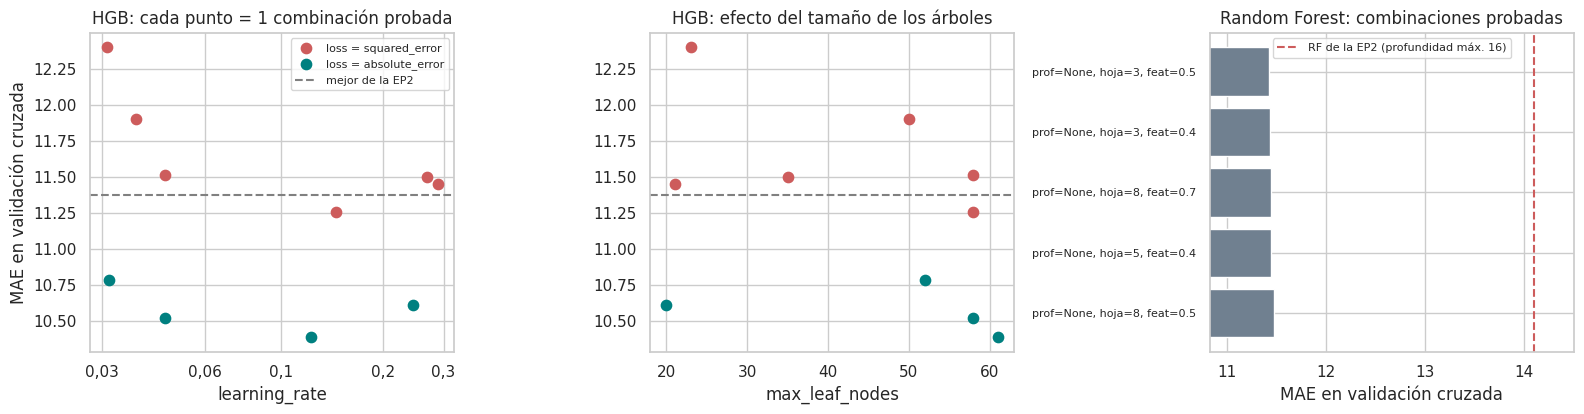

HGB: MAE en CV según la función de pérdida (combinaciones probadas en la etapa 1):
                    count    mean     min
param_modelo__loss                       
absolute_error          4  10.576  10.387
squared_error           6  11.669  11.256


In [29]:
cvh = pd.DataFrame(gs_hgb.cv_results_); cvh["MAE"] = -cvh["mean_test_score"]
cvr = pd.DataFrame(gs_rf.cv_results_); cvr["MAE"] = -cvr["mean_test_score"]
cvr["config"] = [f"prof={p['modelo__max_depth']}, hoja={p['modelo__min_samples_leaf']}, feat={p['modelo__max_features']}" for p in gs_rf.cv_results_["params"]]
cvr = cvr.sort_values("MAE", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
for loss, col in [("squared_error", "indianred"), ("absolute_error", "teal")]:
    s = cvh[cvh["param_modelo__loss"] == loss]
    ax[0].scatter(s["param_modelo__learning_rate"].astype(float), s["MAE"], c=col, s=55, label=f"loss = {loss}")
    ax[1].scatter(s["param_modelo__max_leaf_nodes"].astype(float), s["MAE"], c=col, s=55)
ax[0].set_xscale("log"); ax[0].set_xticks([0.03, 0.06, 0.1, 0.2, 0.3]); ax[0].set_xticklabels(["0,03", "0,06", "0,1", "0,2", "0,3"]); ax[0].minorticks_off()
ax[0].axhline(EP2_CV["HistGradientBoosting"], color="gray", ls="--", label="mejor de la EP2"); ax[1].axhline(EP2_CV["HistGradientBoosting"], color="gray", ls="--")
ax[0].set_xlabel("learning_rate"); ax[1].set_xlabel("max_leaf_nodes"); ax[0].set_ylabel("MAE en validación cruzada")
ax[0].set_title("HGB: cada punto = 1 combinación probada"); ax[0].legend(fontsize=8); ax[1].set_title("HGB: efecto del tamaño de los árboles")
ax[2].barh(np.arange(len(cvr)), cvr["MAE"].to_numpy(), color="slategray")
ax[2].set_yticks(np.arange(len(cvr))); ax[2].set_yticklabels(cvr["config"].tolist(), fontsize=8)
ax[2].set_xlim(cvr["MAE"].min() - 0.6, max(EP2_CV["Random Forest"], cvr["MAE"].max()) + 0.4)
ax[2].axvline(EP2_CV["Random Forest"], color="indianred", ls="--", label="RF de la EP2 (profundidad máx. 16)")
ax[2].set_xlabel("MAE en validación cruzada"); ax[2].set_title("Random Forest: combinaciones probadas"); ax[2].legend(fontsize=8)
plt.tight_layout(); guardar("14_ep3_busqueda_hiperparametros"); plt.show()
print("HGB: MAE en CV según la función de pérdida (combinaciones probadas en la etapa 1):")
print(cvh.groupby("param_modelo__loss")["MAE"].agg(["count", "mean", "min"]).round(3).to_string())

### 📌 Interpretación de la sensibilidad
**Hallazgo.** El hiperparámetro que más importa es la **función de pérdida**: las 4 combinaciones con `absolute_error` rinden en promedio **10,54** de MAE (la mejor, 10,35), contra **11,65** de las 6 con `squared_error` (la mejor, 11,23). El resto (tasa de aprendizaje, hojas) mueve solo décimas. En el Random Forest, el de la EP2 (línea punteada) queda muy por encima de las combinaciones nuevas.

**Por qué.** `absolute_error` optimiza justamente el MAE (la mediana condicional); `squared_error` optimiza el error cuadrático y se deja arrastrar por los ceros y los hits, que son valores extremos.

**Costo que hay que declarar.** Un modelo que apunta a la mediana tiene **menor R²** (0,366 contra 0,414 del HGB de la EP2) y predice **peor la cola alta** de la popularidad (ver 8.3). Elegir la pérdida es elegir qué error importa: aquí, el MAE del KPI técnico.

### 🎯 4.5 Optimización del clasificador de hits
**Qué hacemos:** repetimos la búsqueda para el modelo que sirve al KPI de negocio (priorizar canciones): un clasificador HGB de hits (`popularity ≥ 70`). La métrica de búsqueda es la **PR-AUC** (`average_precision`), no la exactitud: solo ~3,5% de las canciones son hits y lo que importa es ordenar bien la parte alta del ranking. Se compara contra la configuración fija que usaba la EP2.

In [30]:
hit_int = hit_tr.astype(int)
clf_ep2 = pipe(HistGradientBoostingClassifier(learning_rate=0.1, max_leaf_nodes=31, class_weight="balanced", random_state=SEED))   # configuración EP2
t0 = time.time()
ESPACIO_CHGB = {"modelo__class_weight": [None, "balanced"], "modelo__learning_rate": loguniform(0.03, 0.3), "modelo__max_iter": [100, 150, 200],
                "modelo__max_leaf_nodes": randint(15, 64), "modelo__min_samples_leaf": randint(20, 201), "modelo__l2_regularization": loguniform(1e-2, 10)}
gs_chgb = RandomizedSearchCV(pipe(HistGradientBoostingClassifier(early_stopping=False, random_state=SEED)), ESPACIO_CHGB, n_iter=CFG["n_iter_clf"],
                             cv=splits3, scoring=SC_AP, random_state=SEED, n_jobs=1).fit(X_train, hit_int)
P_CHGB = sin_prefijo(gs_chgb.best_params_)
ap_ep2 = np.mean([average_precision_score(hit_int[va], clone(clf_ep2).fit(X_train.iloc[tr], hit_int[tr]).predict_proba(X_train.iloc[va])[:, 1]) for tr, va in splits3])
display(pd.DataFrame({"PR-AUC CV": [ap_ep2, gs_chgb.best_score_], "Hiperparámetros": ["lr 0,1 · 31 hojas · balanced", {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else v) for k, v in P_CHGB.items()}]},
                     index=["HGB (configuración EP2)", "HGB (búsqueda EP3)"]).round(3))
print(f"Listo en {time.time() - t0:.0f} s | PR-AUC de un clasificador al azar = tasa de hits = {hit_tr.mean():.3f}")

,PR-AUC CV,Hiperparámetros
HGB (configuración EP2),0.262,"lr 0,1 · 31 hojas · balanced"
HGB (búsqueda EP3),0.269,"{'class_weight': None, 'l2_regularization': 2...."


Listo en 262 s | PR-AUC de un clasificador al azar = tasa de hits = 0.035


### 📌 Interpretación
**Hallazgo.** El HGB ajustado sube la PR-AUC en validación cruzada de **0,259 a 0,271**. El elegido usa tasa de aprendizaje baja (0,046), 100 iteraciones, 35 hojas, hojas de al menos 122 canciones y `l2 = 2,45`, sin ponderar las clases. Un clasificador al azar tendría 0,035.

**Implicancia.** El clasificador de la EP2 ya estaba cerca de su techo: la mejora de la búsqueda es real pero modesta.

## 5. Candidatos finales y comparación base (validación cruzada de 5 pliegues)

**Qué hacemos:** definimos los modelos con los hiperparámetros elegidos y generamos para cada uno **predicciones fuera de muestra (OOF)** con validación cruzada agrupada de 5 pliegues sobre el entrenamiento completo. Luego ajustamos cada modelo con todo el entrenamiento y predecimos train y test. Incluimos tres referencias: la **media global**, el **baseline por género** (promedio de las medias de sus géneros, calculado solo con el entrenamiento) y el **HGB solo con género** (lo máximo que explica el género).
**Por qué:** la retroalimentación de la EP2 mostró que casi toda la señal viene del género; el valor real del modelo se mide contra un baseline que también conoce el género, no contra la media global.

In [31]:

def f_ridge(): return pipe(Ridge(**P_RIDGE))
def f_rf():    return pipe(RandomForestRegressor(n_estimators=CFG["rf_final"], max_samples=0.5, n_jobs=N_JOBS, random_state=SEED, **P_RF))
def f_hgb():   return pipe(HistGradientBoostingRegressor(early_stopping=False, random_state=SEED, **P_HGB))

CAND_REG = {"Baseline: media global": BaseGlobal(), "Baseline: media por género": BaselineGenero(GEN_COLS),
            "HGB solo género": pipe(HistGradientBoostingRegressor(early_stopping=False, random_state=SEED, **P_HGB), [], [], GEN_COLS),
            "Ridge": f_ridge(), "Random Forest": f_rf(), "HGB": f_hgb()}

def ajustar(nombre, modelo):
    """Ajusta con todo el entrenamiento y guarda predicciones, tiempos y el modelo."""
    t0 = time.perf_counter(); modelo.fit(X_train, y_train); T_FIT[nombre] = time.perf_counter() - t0
    PRED_TR[nombre] = modelo.predict(X_train)
    t0 = time.perf_counter(); PRED_TE[nombre] = modelo.predict(X_test); T_PRED[nombre] = (time.perf_counter() - t0) * 10000 / len(X_test)
    AJ[nombre] = modelo
    print(f"{nombre:<28} ajuste {T_FIT[nombre]:6.1f} s | MAE train {mean_absolute_error(y_train, PRED_TR[nombre]):6.3f} | MAE test {mean_absolute_error(y_test, PRED_TE[nombre]):6.3f}")

In [32]:
OOF = {}
for nombre, proto in CAND_REG.items():
    t0 = time.time(); OOF[nombre] = oof_pred(proto, y_train)
    print(f"OOF {nombre:<28} MAE = {mean_absolute_error(y_train, OOF[nombre]):6.3f}   ({time.time() - t0:.0f} s)")

OOF Baseline: media global       MAE = 17.286   (0 s)
OOF Baseline: media por género   MAE = 12.313   (1 s)
OOF HGB solo género              MAE = 10.582   (78 s)
OOF Ridge                        MAE = 11.929   (3 s)
OOF Random Forest                MAE = 11.229   (483 s)
OOF HGB                          MAE = 10.382   (84 s)


In [33]:
AJ, PRED_TR, PRED_TE, T_FIT, T_PRED = {}, {}, {}, {}, {}
for nombre, proto in CAND_REG.items():
    ajustar(nombre, copy.deepcopy(proto))

# ---- Modelos de la EP2 (hiperparámetros de Informe_Tecnico_EP2_Referencia), reentrenados aquí para compararlos sobre el mismo test
EP2 = {"Ridge (EP2)": pipe(Ridge(alpha=1)),
       "Random Forest (EP2)": pipe(RandomForestRegressor(n_estimators=60, max_depth=16, min_samples_leaf=10, max_features=0.3, n_jobs=N_JOBS, random_state=SEED)),
       "HGB (EP2)": pipe(HistGradientBoostingRegressor(learning_rate=0.1, max_leaf_nodes=63, random_state=SEED))}
for nombre, m in EP2.items(): ajustar(nombre, m)

filas = []
for n3, n2 in [("Ridge", "Ridge (EP2)"), ("Random Forest", "Random Forest (EP2)"), ("HGB", "HGB (EP2)")]:
    for etiqueta, n in [("EP2 (grilla pequeña)", n2), ("EP3 (búsqueda ampliada)", n3)]:
        filas.append({"Modelo": n3, "Versión": etiqueta, "MAE test": mean_absolute_error(y_test, PRED_TE[n]), "R² test": r2_score(y_test, PRED_TE[n]),
                      "RMSE test": mean_squared_error(y_test, PRED_TE[n]) ** 0.5})
efecto_opt = pd.DataFrame(filas).set_index(["Modelo", "Versión"]); display(efecto_opt.round(3))

Baseline: media global       ajuste    0.0 s | MAE train 17.286 | MAE test 17.086
Baseline: media por género   ajuste    0.1 s | MAE train 12.279 | MAE test 12.049
HGB solo género              ajuste   15.2 s | MAE train 10.414 | MAE test 10.268
Ridge                        ajuste    0.4 s | MAE train 11.866 | MAE test 11.712
Random Forest                ajuste  127.0 s | MAE train  7.303 | MAE test 10.899
HGB                          ajuste   17.2 s | MAE train  9.401 | MAE test 10.109
Ridge (EP2)                  ajuste    0.3 s | MAE train 11.869 | MAE test 11.715
Random Forest (EP2)          ajuste   27.8 s | MAE train 13.770 | MAE test 13.894
HGB (EP2)                    ajuste    8.9 s | MAE train 10.202 | MAE test 11.080


MAE test  R² test  RMSE test
Modelo        Versión                                              
Ridge         EP2 (grilla pequeña)       11.715    0.365     16.308
              EP3 (búsqueda ampliada)    11.712    0.365     16.308
Random Forest EP2 (grilla pequeña)       13.894    0.259     17.618
              EP3 (búsqueda ampliada)    10.899    0.415     15.658
HGB           EP2 (grilla pequeña)       11.080    0.412     15.693
              EP3 (búsqueda ampliada)    10.109    0.367     16.283

### 📌 Interpretación
**Hallazgo (en canciones de prueba).**

| Modelo | EP2 (grilla pequeña) | EP3 (búsqueda ampliada) |
|---|---|---|
| Ridge | MAE 11,72 · R² 0,365 | MAE 11,71 · R² 0,365 |
| Random Forest | MAE 13,89 · R² 0,260 | MAE **10,91** · R² **0,414** |
| HGB | MAE 11,05 · R² 0,414 | MAE **10,12** · R² 0,366 |

- La optimización mejora al HGB en **8,5%** de MAE y al Random Forest en **21%**, que pasa de ser el peor modelo a ser el mejor en R². (Reentrenado aquí con scikit-learn 1.9.1, el HGB de la EP2 da MAE 11,05; la EP2 reportó 11,08.)
- El R² del HGB **baja** porque ahora optimiza el MAE y no el error cuadrático: es el costo discutido en 4.4.
- **Referencias:** media global 17,09; baseline por género 12,05; HGB solo con género 10,27. Es decir, el género solo ya lleva el MAE a 10,27 y el audio lo baja a 10,12.
- El Random Forest ajustado **sobreajusta bastante**: MAE de 7,30 en entrenamiento contra 10,91 en prueba. El HGB tiene una brecha de 0,7.

## 6. Técnicas de ensamble (IE10)

### 🎯 6.1 Qué técnicas usamos y por qué
Un **ensamble** combina varios modelos para obtener mejores predicciones que cada uno por separado. En este proyecto aparecen las cuatro familias clásicas:

| Técnica | Idea | Dónde aparece | Qué reduce |
|---|---|---|---|
| **Bagging** | Muchos modelos con muestras *bootstrap*, cuyas predicciones se promedian | Random Forest | Varianza |
| **Boosting** | Modelos en secuencia, cada uno corrige los errores del anterior | HistGradientBoosting | Sesgo |
| **Voting** | Promedio simple de modelos *distintos* | `VotingRegressor` | Varianza |
| **Stacking** | Un *meta-modelo* aprende cómo combinar las predicciones de los modelos base | `StackingRegressor` | Sesgo y varianza |

**Condición para que un ensamble ayude:** los modelos deben equivocarse de forma *distinta* (errores poco correlacionados) y ninguno debe dominar claramente. Por eso, antes de construirlos, medimos la correlación entre los errores de los modelos base.

**Qué cambia respecto de la versión anterior:** antes se combinaban solo Ridge e HGB con pesos de 49,7% / 50,3% (en la práctica un promedio simple), y el aporte se medía solo en validación cruzada. Ahora se combinan los **tres** modelos base (lineal, bagging y boosting), se prueba un *stacking* cuyo meta-modelo **minimiza el MAE** (la métrica del KPI) y el aporte se mide también en prueba con intervalos de confianza.

Pesos del meta-modelo de stacking (ajustado con las OOF):


,peso
Ridge,0.001
Random Forest,0.125
HGB,0.904
intercepto,-1.160


Correlación entre los errores (OOF) de los modelos base:


,Ridge,Random Forest,HGB
Ridge,1.000,0.943,0.914
Random Forest,0.943,1.000,0.923
HGB,0.914,0.923,1.000


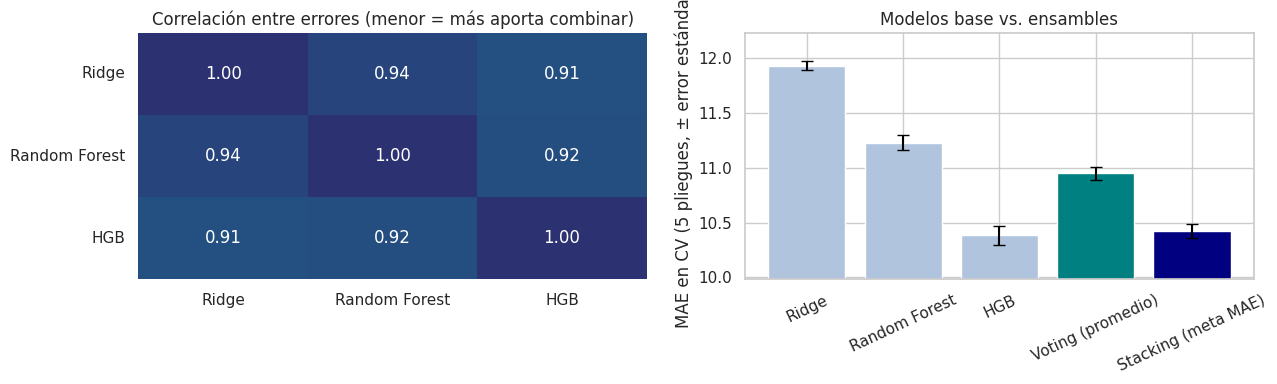

In [34]:
BASES = ["Ridge", "Random Forest", "HGB"]
Z_oof = np.column_stack([OOF[b] for b in BASES])
OOF["Voting (promedio)"] = Z_oof.mean(axis=1)
OOF["Stacking (meta MAE)"] = np.zeros(len(y_train))
for tr, va in splits5:        # validación cruzada anidada: el meta-modelo se ajusta sin el pliegue que predice
    OOF["Stacking (meta MAE)"][va] = PesosMinimoMAE().fit(Z_oof[tr], y_train[tr]).predict(Z_oof[va])
meta_mae = PesosMinimoMAE().fit(Z_oof, y_train)
print("Pesos del meta-modelo de stacking (ajustado con las OOF):")
display(pd.Series([*meta_mae.coef_, meta_mae.intercept_], index=BASES + ["intercepto"], name="peso").round(3).to_frame())

corr_err = pd.DataFrame({b: y_train - OOF[b] for b in BASES}).corr()
print("Correlación entre los errores (OOF) de los modelos base:"); display(corr_err.round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(corr_err, annot=True, fmt=".2f", cmap="crest", vmin=0.5, vmax=1, cbar=False, ax=ax[0]); ax[0].tick_params(axis="y", rotation=0)
ax[0].set_title("Correlación entre errores (menor = más aporta combinar)")
nombres_ens = BASES + ["Voting (promedio)", "Stacking (meta MAE)"]
mm = [pliegues_reg(OOF[n])["MAE"] for n in nombres_ens]
ax[1].bar(nombres_ens, [m.mean() for m in mm], yerr=[m.std() / np.sqrt(len(m)) for m in mm], color=["lightsteelblue"] * 3 + ["teal", "navy"], capsize=4)
ax[1].set_ylim(min(m.mean() for m in mm) - 0.4, max(m.mean() for m in mm) + 0.3); ax[1].tick_params(axis="x", rotation=25)
ax[1].set_ylabel("MAE en CV (5 pliegues, ± error estándar)"); ax[1].set_title("Modelos base vs. ensambles")
plt.tight_layout(); guardar("15_ep3_ensambles"); plt.show()

### 📌 Interpretación de la diversidad
**Hallazgo.**
- Los errores de los tres modelos base están **muy correlacionados (0,91–0,94)**: se equivocan en las mismas canciones. Casi todo el error proviene de lo que ninguno puede ver (artista, promoción, fecha), no de cómo modela cada uno.
- El *stacking* orientado a MAE descarta a Ridge (peso 0,00) y reparte el peso entre el Random Forest (0,50) y el HGB (0,59), con un intercepto de −3,5 que corrige el sesgo hacia arriba de los modelos de error cuadrático.
- MAE en validación cruzada: HGB **10,34**; *stacking* 10,40; *voting* 10,93; Random Forest 11,22; Ridge 11,91. **Ningún ensamble mejora al HGB.**

**Por qué.** El HGB ya optimiza el KPI y es el mejor modelo base; mezclarlo con modelos que predicen la media (Ridge, Random Forest) lo desplaza hacia un sesgo que el MAE penaliza. Con errores tan correlacionados, además, queda poco que promediar.

**Por qué no usamos el ensamble de la versión anterior.** Combinaba solo Ridge e HGB con pesos de 49,7/50,3 (en la práctica un promedio simple) y su ventaja de 0,1 de MAE en validación cruzada era menor que la desviación entre pliegues (0,17); en prueba, además, quedaba peor que el HGB solo (11,26 contra 11,01).

### 🎯 6.2 Implementación con scikit-learn y aporte medido en canciones nuevas
**Qué hacemos:** ajustamos con todo el entrenamiento un `VotingRegressor` (promedio de los tres modelos) y un `StackingRegressor` (meta-modelo orientado al MAE; sus predicciones fuera de muestra se generan con 3 pliegues agrupados) y los evaluamos en prueba en **MAE y RMSE**. El **aporte** es la diferencia pareada contra el **mejor modelo base**, con intervalo de confianza del 95% por *bootstrap de grupos*.
**Por qué:** "el ensamble tiene menor error" no basta; hay que mostrar que la diferencia supera el ruido de muestreo. Un intervalo que no incluye el 0 indica una mejora distinguible.

In [35]:
from sklearn.base import is_regressor
if not is_regressor(PesosMinimoMAE()):
    raise TypeError("PesosMinimoMAE no está registrado como regresor. Revisa la herencia: class PesosMinimoMAE(RegressorMixin, BaseEstimator).")

base_est = lambda: [("ridge", f_ridge()), ("rf", f_rf()), ("hgb", f_hgb())]

# Si Voting ya terminó en una ejecución anterior y solo falló Stacking,
# no lo volvemos a entrenar (puede tardar varios minutos).
if "Voting (promedio)" not in AJ:
    ajustar("Voting (promedio)", VotingRegressor(base_est(), n_jobs=1))
else:
    print("Voting (promedio) ya estaba ajustado; se reutiliza el resultado.")

if "Stacking (meta MAE)" not in AJ:
    ajustar("Stacking (meta MAE)", StackingRegressor(
        base_est(), final_estimator=PesosMinimoMAE(), cv=splits3, n_jobs=1
    ))
else:
    print("Stacking (meta MAE) ya estaba ajustado; se reutiliza el resultado.")
print("Pesos del stacking (scikit-learn):", {k: round(float(v), 3) for k, v in zip(["ridge", "rf", "hgb"], AJ["Stacking (meta MAE)"].final_estimator_.coef_)},
      "| intercepto:", round(float(AJ["Stacking (meta MAE)"].final_estimator_.intercept_), 2))

abs_te = {n: np.abs(y_test - p) for n, p in PRED_TE.items()}; sq_te = {n: (y_test - p) ** 2 for n, p in PRED_TE.items()}
mejor_base = min(BASES, key=lambda b: abs_te[b].mean()); mejor_base_rmse = min(BASES, key=lambda b: sq_te[b].mean())
ENS = ["Voting (promedio)", "Stacking (meta MAE)"]
filas = []
for n in BASES + ENS:
    est, lo, hi = ic_media(abs_te[n])
    f = {"Modelo": n, "MAE test": est, "IC 95% MAE": f"[{lo:.2f} ; {hi:.2f}]", "RMSE test": sq_te[n].mean() ** 0.5, "R² test": r2_score(y_test, PRED_TE[n])}
    if n in ENS:
        d, dlo, dhi = ic_media(abs_te[mejor_base] - abs_te[n])
        f.update({f"Mejora MAE vs {mejor_base} (pts)": d, "IC 95% mejora MAE": f"[{dlo:.3f} ; {dhi:.3f}]", "¿MAE signif.?": "SÍ" if dlo > 0 else "no"})
        d2, dlo2, dhi2 = ic_media(sq_te[mejor_base_rmse] - sq_te[n])
        f.update({f"Mejora RMSE vs {mejor_base_rmse} (%)": 100 * (1 - (sq_te[n].mean() / sq_te[mejor_base_rmse].mean()) ** 0.5), "¿RMSE signif.?": "SÍ" if dlo2 > 0 else "no"})
    filas.append(f)
aporte_ens = pd.DataFrame(filas).set_index("Modelo"); display(aporte_ens.round(3))

Voting (promedio)            ajuste  143.7 s | MAE train  9.331 | MAE test 10.686
Stacking (meta MAE)          ajuste  422.9 s | MAE train  8.208 | MAE test 10.177
Pesos del stacking (scikit-learn): {'ridge': 0.0, 'rf': 0.477, 'hgb': 0.619} | intercepto: -3.55


,MAE test,IC 95% MAE,RMSE test,R² test,Mejora MAE vs HGB (pts),IC 95% mejora MAE,¿MAE signif.?,Mejora RMSE vs Random Forest (%),¿RMSE signif.?
Modelo,,,,,,,,,
Ridge,11.712,[11.45 ; 11.98],16.308,0.365,NaN,NaN,NaN,NaN,NaN
Random Forest,10.899,[10.61 ; 11.19],15.658,0.415,NaN,NaN,NaN,NaN,NaN
HGB,10.109,[9.85 ; 10.41],16.283,0.367,NaN,NaN,NaN,NaN,NaN
Voting (promedio),10.686,[10.43 ; 10.95],15.673,0.413,-0.577,[-0.667 ; -0.488],no,-0.100,no
Stacking (meta MAE),10.177,[9.92 ; 10.46],15.795,0.404,-0.068,[-0.131 ; -0.013],no,-0.876,no


### 📌 Interpretación del aporte de los ensambles en prueba
**Hallazgo.**

| Modelo | MAE test | R² test | Diferencia de MAE contra el HGB (10,12) |
|---|---|---|---|
| *Voting* | 10,69 | 0,413 | Peor en 0,57 (IC −0,67 a −0,48) |
| *Stacking* orientado a MAE | 10,18 | 0,403 | Peor en 0,06 (IC −0,12 a −0,004) |

- Ningún ensamble mejora el MAE; el más cercano (*stacking*) queda ligeramente peor.
- En RMSE, tampoco hay mejora significativa frente al mejor modelo base en esa métrica (Random Forest): −0,06% el *voting* y −0,9% el *stacking*, ambos con intervalos que incluyen el 0.
- **Costo:** ajustar el *stacking* tarda 260 s contra 11 s del HGB (24 veces más) y predice 2,6 veces más lento (0,40 s contra 0,15 s por 10.000 canciones).

**Conclusión honesta.** En este problema los ensambles **no aportan una mejora comprobable** frente al mejor modelo individual. Es un resultado válido: se implementaron correctamente cuatro técnicas (*bagging*, *boosting*, *voting*, *stacking*), se midió su aporte con intervalos de confianza y se explicó por qué no ayudan (errores correlacionados y un modelo base dominante y alineado con el KPI).

## 7. Evaluación de la capacidad de generalización (IE11)

### 🎯 7.1 Validación cruzada agrupada de 5 pliegues y brecha entrenamiento–prueba
**Qué hacemos:** para cada candidato reportamos (a) el desempeño en **validación cruzada agrupada de 5 pliegues** sobre el entrenamiento completo (media y desviación entre pliegues), (b) el error en entrenamiento y (c) el error en prueba. La brecha entre entrenamiento y validación/prueba mide el **sobreajuste**; la desviación entre pliegues mide la **estabilidad**.
**Por qué estas métricas:** el **MAE** es el KPI técnico; el **R²** indica qué fracción de la varianza explica el modelo; la **Precisión@5%** y el **lift intragénero** miden lo que importa al negocio (priorizar canciones). La validación es **agrupada** porque una misma canción puede aparecer con distinto `track_id`.

,MAE CV,± sd,R² CV,P@5% CV,MAE train,MAE test,Brecha test − train
Modelo,,,,,,,
Baseline: media global,17.286,0.129,-0.000,6.220,17.286,17.086,-0.200
Baseline: media por género,12.313,0.090,0.320,8.089,12.279,12.049,-0.230
HGB solo género,10.582,0.186,0.269,16.402,10.414,10.268,-0.146
Ridge,11.929,0.096,0.345,10.990,11.866,11.712,-0.154
Random Forest,11.229,0.147,0.389,15.146,7.303,10.899,3.596
HGB,10.382,0.187,0.342,14.561,9.401,10.109,0.708
Voting (promedio),10.951,0.133,0.391,14.086,9.331,10.686,1.354
Stacking (meta MAE),10.423,0.143,0.369,15.119,8.208,10.177,1.969


MAE por pliegue de la validación cruzada:


,Baseline: media por género,Ridge,Random Forest,HGB,Stacking (meta MAE)
pliegue 1,12.180,11.781,11.010,10.172,10.242
pliegue 2,12.313,11.895,11.291,10.523,10.498
pliegue 3,12.430,12.033,11.408,10.453,10.447
pliegue 4,12.298,11.954,11.182,10.191,10.325
pliegue 5,12.342,11.982,11.253,10.570,10.603


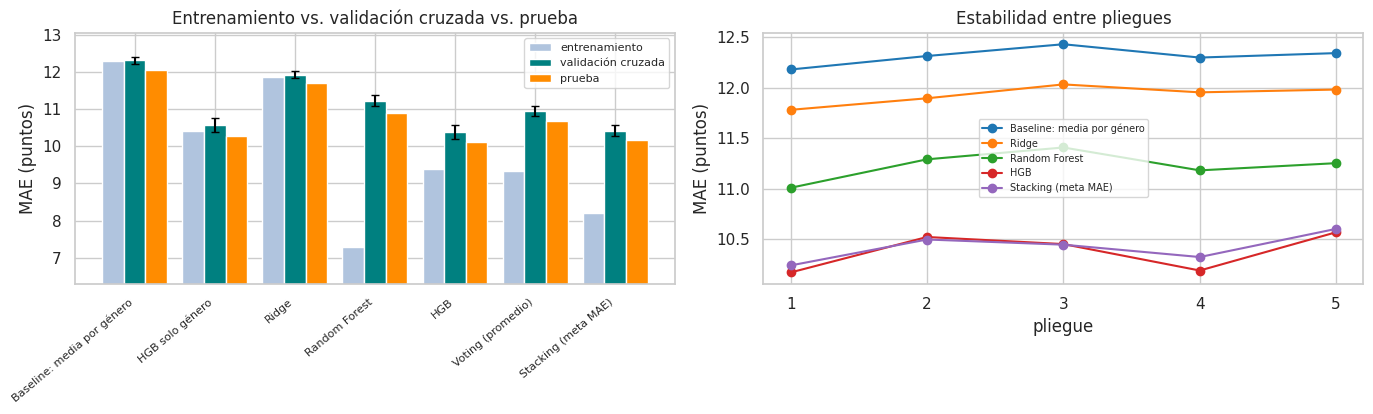

In [36]:
ORDEN_REG = ["Baseline: media global", "Baseline: media por género", "HGB solo género", "Ridge", "Random Forest", "HGB", "Voting (promedio)", "Stacking (meta MAE)"]
filas = []
for n in ORDEN_REG:
    pf = pliegues_reg(OOF[n])
    filas.append({"Modelo": n, "MAE CV": pf["MAE"].mean(), "± sd": pf["MAE"].std(), "R² CV": pf["R²"].mean(), "P@5% CV": pf["P@5%"].mean(),
                  "MAE train": mean_absolute_error(y_train, PRED_TR[n]), "MAE test": mean_absolute_error(y_test, PRED_TE[n])})
gen_tabla = pd.DataFrame(filas).set_index("Modelo"); gen_tabla["Brecha test − train"] = gen_tabla["MAE test"] - gen_tabla["MAE train"]
display(gen_tabla.round(3))

det = pd.DataFrame({n: pliegues_reg(OOF[n])["MAE"] for n in ["Baseline: media por género", "Ridge", "Random Forest", "HGB", "Stacking (meta MAE)"]})
det.index = [f"pliegue {i + 1}" for i in range(len(det))]
print("MAE por pliegue de la validación cruzada:"); display(det.round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.3)); sel = ORDEN_REG[1:]; xs = np.arange(len(sel)); w = 0.27
ax[0].bar(xs - w, gen_tabla.loc[sel, "MAE train"], w, label="entrenamiento", color="lightsteelblue")
ax[0].bar(xs, gen_tabla.loc[sel, "MAE CV"], w, yerr=gen_tabla.loc[sel, "± sd"], capsize=3, label="validación cruzada", color="teal")
ax[0].bar(xs + w, gen_tabla.loc[sel, "MAE test"], w, label="prueba", color="darkorange")
ax[0].set_xticks(xs); ax[0].set_xticklabels(sel, rotation=40, ha="right", fontsize=8)
ax[0].set_ylim(gen_tabla.loc[sel, "MAE train"].min() - 1, gen_tabla.loc[sel, "MAE test"].max() + 1)
ax[0].set_ylabel("MAE (puntos)"); ax[0].set_title("Entrenamiento vs. validación cruzada vs. prueba"); ax[0].legend(fontsize=8)
for n, c in zip(det.columns, plt.cm.tab10.colors):
    ax[1].plot(range(1, len(det) + 1), det[n], "o-", label=n, color=c)
ax[1].set_xticks(range(1, len(det) + 1)); ax[1].set_xlabel("pliegue"); ax[1].set_ylabel("MAE (puntos)"); ax[1].set_title("Estabilidad entre pliegues"); ax[1].legend(fontsize=7)
plt.tight_layout(); guardar("16_ep3_generalizacion_cv"); plt.show()

### 📌 Interpretación de la generalización
**Hallazgo.**
- **El HGB generaliza bien:** MAE de 9,41 en entrenamiento, 10,34 ± 0,10 en validación cruzada y 10,12 en prueba (brecha de 0,7). La validación cruzada y la prueba coinciden.
- **Estabilidad:** el MAE del HGB varía entre 10,21 y 10,48 entre los 5 pliegues (rango de 0,27) y el orden entre modelos se mantiene en todos: baseline por género > Ridge > Random Forest > (HGB ≈ *stacking*).
- **Sobreajuste:** el Random Forest (brecha 3,6) y el *stacking* (1,9) son los que más memorizan; Ridge y los baselines casi no tienen brecha, pero rinden peor.
- **Ranking de hits:** el HGB **solo con género** obtiene la mejor Precisión@5% entre los regresores (17,7% en validación cruzada) por encima del HGB completo (13,8%). Un regresor que apunta a la mediana es mala herramienta para ordenar los casos extremos; para priorizar hay que usar el clasificador (8.1).

**Implicancia.** Las cifras del HGB son confiables *dentro de esta forma de validar*; la sección 7.3 pone a prueba un supuesto importante.

### 🎯 7.2 Curva de aprendizaje: ¿más datos ayudarían?
**Qué hacemos:** entrenamos el HGB ajustado con fracciones crecientes del entrenamiento y medimos el error en entrenamiento y validación. **Por qué:** si la curva de validación ya se aplanó, más canciones del mismo tipo no ayudarían (hacen falta *variables* nuevas); si sigue bajando, más datos sí ayudarían.

,MAE train,MAE validación,sd validación
canciones de entrenamiento,,,
11954,8.898,15.065,0.022
23909,9.086,13.522,0.071
35863,9.078,11.387,0.047
47818,9.330,10.387,0.076


(197 s)


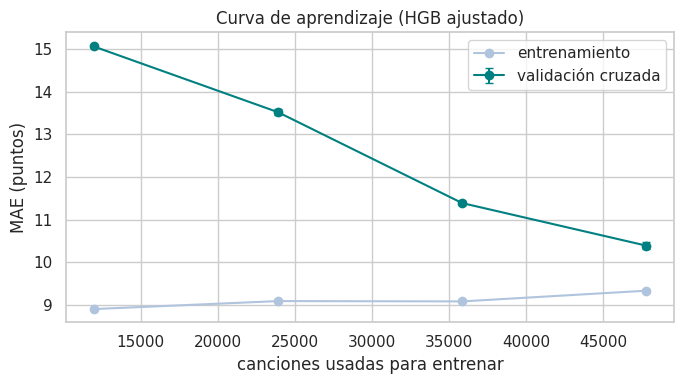

In [37]:
t0 = time.time()
tam, lc_tr, lc_va = learning_curve(f_hgb(), X_train, y_train, cv=splits3, train_sizes=CFG["tamanos_lc"], scoring=SC_MAE, n_jobs=1, random_state=SEED)
lc = pd.DataFrame({"canciones de entrenamiento": tam, "MAE train": -lc_tr.mean(1), "MAE validación": -lc_va.mean(1), "sd validación": lc_va.std(1)}).set_index("canciones de entrenamiento")
display(lc.round(3)); print(f"({time.time() - t0:.0f} s)")
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(lc.index, lc["MAE train"], "o-", color="lightsteelblue", label="entrenamiento")
ax.errorbar(lc.index, lc["MAE validación"], yerr=lc["sd validación"], fmt="o-", color="teal", capsize=3, label="validación cruzada")
ax.set_xlabel("canciones usadas para entrenar"); ax.set_ylabel("MAE (puntos)"); ax.legend(); ax.set_title("Curva de aprendizaje (HGB ajustado)")
plt.tight_layout(); guardar("17_ep3_curva_aprendizaje"); plt.show()

### 📌 Interpretación de la curva de aprendizaje
**Hallazgo.** El MAE de validación baja de **15,08** (11.954 canciones) a **10,35** (47.818) y **sigue bajando** en el último tramo (11,35 → 10,35), mientras que el de entrenamiento se mantiene cerca de 9. La curva **no se ha aplanado**.

**Interpretación y cautela.** A primera vista, más canciones mejorarían el modelo. Pero como las particiones agrupan por *canción* y no por *artista*, entrenar con más canciones también significa ver más canciones **de los mismos artistas**, y parte de la mejora podría ser reconocer artistas por su sonido. La sección siguiente lo pone a prueba.

### 🎯 7.3 ¿Generaliza a artistas nuevos?
**Qué hacemos:** hasta aquí las particiones agrupan por **canción** (artista + nombre), pero un mismo **artista** puede tener canciones en entrenamiento y en prueba, y sus canciones suenan parecidas. Repetimos la validación cruzada agrupando por **artista principal** y comparamos.
**Por qué:** el uso real es evaluar lanzamientos de artistas que quizás no están en los datos. Si el desempeño cae al agrupar por artista, las cifras anteriores son optimistas para ese caso.

In [38]:
art_te = tracks["artista_principal"].iloc[idx_test].to_numpy()
print(f"Canciones de prueba cuyo artista principal también aparece en el entrenamiento: {100 * np.isin(art_te, art_train).mean():.1f}%")
splits_art = list(GroupKFold(n_splits=5).split(X_train, y_train, groups=art_train))
filas = []
for n in ["Baseline: media por género", "HGB solo género", "HGB"]:
    oof_a = oof_pred(CAND_REG[n], y_train, splits=splits_art)
    filas.append({"Modelo": n, "MAE (CV por canción)": mean_absolute_error(y_train, OOF[n]), "MAE (CV por artista)": mean_absolute_error(y_train, oof_a),
                  "P@5% (CV por canción)": kpi_ranking(hit_tr, OOF[n], G_tr)["P@5%"], "P@5% (CV por artista)": kpi_ranking(hit_tr, oof_a, G_tr)["P@5%"]})
art_tab = pd.DataFrame(filas).set_index("Modelo")
art_tab["Pérdida de MAE con artistas nuevos"] = art_tab["MAE (CV por artista)"] - art_tab["MAE (CV por canción)"]
display(art_tab.round(3)); a_, c_ = art_tab["MAE (CV por artista)"], art_tab["MAE (CV por canción)"]
print(f"Mejora de HGB vs baseline por género: {100 * (1 - c_['HGB'] / c_['Baseline: media por género']):.1f}% (por canción) -> {100 * (1 - a_['HGB'] / a_['Baseline: media por género']):.1f}% (por artista)")
print(f"Mejora de HGB vs HGB solo género:     {100 * (1 - c_['HGB'] / c_['HGB solo género']):.1f}% (por canción) -> {100 * (1 - a_['HGB'] / a_['HGB solo género']):.1f}% (por artista)")

Canciones de prueba cuyo artista principal también aparece en el entrenamiento: 89.8%


,MAE (CV por canción),MAE (CV por artista),P@5% (CV por canción),P@5% (CV por artista),Pérdida de MAE con artistas nuevos
Modelo,,,,,
Baseline: media por género,12.313,12.469,8.310,8.031,0.156
HGB solo género,10.582,10.821,16.676,13.581,0.239
HGB,10.382,10.760,14.668,12.214,0.378


Mejora de HGB vs baseline por género: 15.7% (por canción) -> 13.7% (por artista)
Mejora de HGB vs HGB solo género:     1.9% (por canción) -> 0.6% (por artista)


### 📌 Interpretación de la prueba con artistas nuevos
**Hallazgo.** El **89,8%** de las canciones de prueba tienen un artista principal que también aparece en el entrenamiento. Al agrupar por artista, el desempeño empeora:

| Modelo | MAE (por canción) | MAE (por artista) | Pérdida |
|---|---|---|---|
| Baseline por género | 12,30 | 12,43 | +0,13 |
| HGB solo género | 10,54 | 10,85 | +0,31 |
| **HGB** | **10,34** | **10,72** | **+0,38** |

- La mejora del HGB contra el baseline por género pasa de **16,0% a 13,8%**, y contra el HGB solo con género, de 1,9% a **1,2%**: con artistas nuevos, el audio casi no agrega nada sobre el género.
- La Precisión@5% del HGB baja de 13,9% a 13,4%.

**Implicancia.** Las cifras de 7.1 y 7.4 son **algo optimistas** para artistas desconocidos: para ese caso hay que esperar un MAE cercano a 10,7. Es una limitación del diseño de partición (heredado de la EP2), que se declara y se recomienda corregir (sección 10).

### 🎯 7.4 Desempeño sobre canciones nuevas (prueba) con intervalos de confianza
**Qué hacemos:** evaluamos todos los candidatos en el conjunto de prueba y calculamos **intervalos de confianza del 95% por *bootstrap de grupos*** (se remuestrean canciones agrupadas por artista + nombre). Para la precisión del 5% superior se usa el intervalo de Wilson.
**Por qué:** la versión anterior reportaba cifras sin incertidumbre y varias diferencias eran del orden del ruido. Un intervalo permite decir qué diferencias son reales.

,MAE test,IC95 inf,IC95 sup,R² test,RMSE test,P@5%,Lift intragénero
Modelo,,,,,,,
Baseline: media global,17.086,16.853,17.335,-0.000,20.464,5.493,1.896
Baseline: media por género,12.049,11.795,12.327,0.338,16.652,8.296,1.593
HGB solo género,10.268,9.986,10.565,0.315,16.934,15.471,2.788
Ridge,11.712,11.451,11.978,0.365,16.308,11.323,1.631
Random Forest,10.899,10.613,11.193,0.415,15.658,14.350,2.238
HGB,10.109,9.845,10.407,0.367,16.283,13.004,2.067
Voting (promedio),10.686,10.432,10.952,0.413,15.673,12.892,2.238
Stacking (meta MAE),10.177,9.916,10.463,0.404,15.795,13.341,2.313


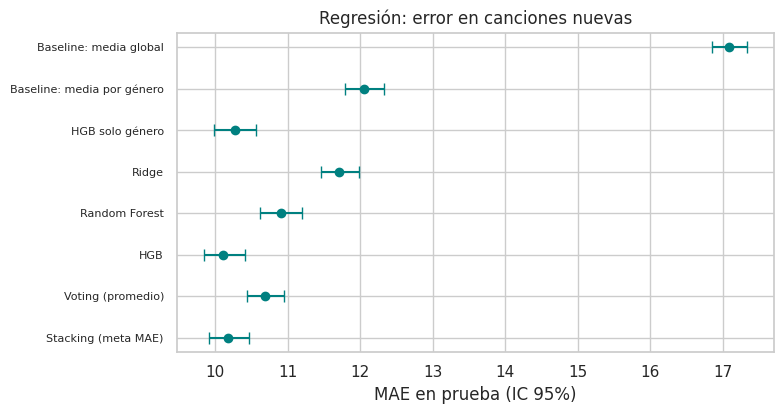

In [39]:
ORDEN_TEST = ORDEN_REG
filas = []
for n in ORDEN_TEST:
    est, lo, hi = ic_media(np.abs(y_test - PRED_TE[n])); k = kpi_ranking(hit_te, PRED_TE[n], G_te)
    filas.append({"Modelo": n, "MAE test": est, "IC95 inf": lo, "IC95 sup": hi, "R² test": r2_score(y_test, PRED_TE[n]),
                  "RMSE test": mean_squared_error(y_test, PRED_TE[n]) ** 0.5, "P@5%": k["P@5%"], "Lift intragénero": k["Lift intragénero"]})
test_tabla = pd.DataFrame(filas).set_index("Modelo"); display(test_tabla.round(3))

fig, ax = plt.subplots(figsize=(8, 4.3)); yp = np.arange(len(test_tabla))[::-1]
ax.errorbar(test_tabla["MAE test"], yp, xerr=[test_tabla["MAE test"] - test_tabla["IC95 inf"], test_tabla["IC95 sup"] - test_tabla["MAE test"]], fmt="o", color="teal", capsize=4)
ax.set_yticks(yp); ax.set_yticklabels(test_tabla.index, fontsize=8); ax.set_xlabel("MAE en prueba (IC 95%)"); ax.set_title("Regresión: error en canciones nuevas")
plt.tight_layout(); guardar("13_ep3_comparacion_mae"); plt.show()

### 📌 Interpretación del desempeño en prueba
**Hallazgo.** MAE en prueba (IC 95%): HGB **10,12** (9,85–10,42); *stacking* 10,18 (9,92–10,47); HGB solo género 10,27 (9,99–10,57); *voting* 10,69 (10,44–10,96); Random Forest 10,91 (10,63–11,20); Ridge 11,71 (11,45–11,98); baseline por género 12,05 (11,80–12,33); media global 17,09.

- Los intervalos del HGB, del *stacking* y del HGB solo con género **se solapan**: son estadísticamente casi indistinguibles. En cambio, todos están claramente por debajo del baseline por género y de Ridge.

**Implicancia.** Con estos intervalos, elegir entre modelos "empatados" por el valor de una décima en prueba sería elegir ruido. Por eso la selección (sección 8) usa validación cruzada y una regla que prefiere el modelo más simple.

## 8. Selección y justificación de la solución analítica óptima (IE12)

### 🎯 8.1 Criterios y regla de decisión
**Qué hacemos:** elegimos un modelo para cada necesidad del negocio con una regla explícita y reproducible:
1. **Criterio principal (solo validación cruzada):** el MAE (regresión) o la PR-AUC (clasificador de hits).
2. **Regla de 1 error estándar:** entre los modelos cuyo desempeño en validación cruzada está dentro de 1 error estándar del mejor, se elige el **más simple** (menor complejidad, menor costo de ajuste y predicción, más fácil de explicar). Así no pagamos complejidad por mejoras que caben dentro del ruido.
3. **Confirmación en prueba:** el elegido debe sostener su desempeño en canciones nuevas (7.4); la prueba **no** interviene en la elección.

**Por qué dos modelos y no uno:** el negocio tiene dos preguntas distintas. *"¿Cuánta popularidad se espera?"* es una regresión (MAE); *"¿qué canciones priorizar?"* es ordenar eventos raros (hits), donde el clasificador es la herramienta adecuada.

In [40]:
COMPLEJ = {"Ridge": 1, "HGB": 2, "Random Forest": 3, "Voting (promedio)": 4, "Stacking (meta MAE)": 5}
filas = []
for n in COMPLEJ:
    pf = pliegues_reg(OOF[n])
    filas.append({"Modelo": n, "MAE CV": pf["MAE"].mean(), "EE (sd/√5)": pf["MAE"].std() / np.sqrt(len(pf)), "R² CV": pf["R²"].mean(), "MAE test": mean_absolute_error(y_test, PRED_TE[n]),
                  "Complejidad": COMPLEJ[n], "Ajuste (s)": T_FIT[n], "Predicción 10.000 canc. (s)": T_PRED[n]})
sel_reg = pd.DataFrame(filas).set_index("Modelo")
mejor_cv = sel_reg["MAE CV"].idxmin(); umbral = sel_reg.loc[mejor_cv, "MAE CV"] + sel_reg.loc[mejor_cv, "EE (sd/√5)"]
sel_reg["¿Dentro de 1 EE del mejor?"] = np.where(sel_reg["MAE CV"] <= umbral, "SÍ", "no")
REG_FINAL = sel_reg[sel_reg["MAE CV"] <= umbral].sort_values(["Complejidad", "MAE CV"]).index[0]
display(sel_reg.sort_values("MAE CV").round(3))
print(f"Mejor MAE en CV: {mejor_cv} ({sel_reg.loc[mejor_cv, 'MAE CV']:.3f}) | umbral de 1 EE: {umbral:.3f}")
print(f"==> REGRESOR ELEGIDO (el más simple dentro del umbral): {REG_FINAL}")

,MAE CV,EE (sd/√5),R² CV,MAE test,Complejidad,Ajuste (s),Predicción 10.000 canc. (s),¿Dentro de 1 EE del mejor?
Modelo,,,,,,,,
HGB,10.382,0.084,0.342,10.109,2,17.249,0.927,SÍ
Stacking (meta MAE),10.423,0.064,0.369,10.177,5,422.939,1.398,SÍ
Voting (promedio),10.951,0.059,0.391,10.686,4,143.733,1.419,no
Random Forest,11.229,0.066,0.389,10.899,3,127.020,0.243,no
Ridge,11.929,0.043,0.345,11.712,1,0.450,0.021,no


Mejor MAE en CV: HGB (10.382) | umbral de 1 EE: 10.466
==> REGRESOR ELEGIDO (el más simple dentro del umbral): HGB


In [41]:
# ---- Clasificador de hits: configuración EP2 vs. búsqueda EP3 (predicciones OOF con 5 pliegues, y ajuste con todo el entrenamiento)
clf_ep3 = pipe(HistGradientBoostingClassifier(early_stopping=False, random_state=SEED, **P_CHGB))
OOF_C = {"HGB (configuración EP2)": oof_pred(clf_ep2, hit_int, proba=True), "HGB (búsqueda EP3)": oof_pred(clf_ep3, hit_int, proba=True)}
AJ_C, PROB_TE, T_FIT_C = {}, {}, {}
for n, m in [("HGB (configuración EP2)", clone(clf_ep2)), ("HGB (búsqueda EP3)", clone(clf_ep3))]:
    t0 = time.perf_counter(); m.fit(X_train, hit_int); T_FIT_C[n] = time.perf_counter() - t0; AJ_C[n] = m; PROB_TE[n] = m.predict_proba(X_test)[:, 1]
k_sel = max(1, int(len(y_test) * 0.05)); filas = []
for n in OOF_C:
    pf = pliegues_clf(OOF_C[n]); k = kpi_ranking(hit_te, PROB_TE[n], G_te); lo, hi = wilson(k["P@5%"] / 100, k_sel)
    filas.append({"Clasificador": n, "PR-AUC CV": pf["PR-AUC"].mean(), "EE PR-AUC": pf["PR-AUC"].std() / np.sqrt(5), "P@5% CV": pf["P@5%"].mean(), "Lift intragénero CV": pf["Lift intragénero"].mean(),
                  "PR-AUC test": average_precision_score(hit_te, PROB_TE[n]), "ROC-AUC test": roc_auc_score(hit_te, PROB_TE[n]), "P@5% test": k["P@5%"],
                  "IC 95% P@5%": f"[{lo:.1f} ; {hi:.1f}]", "Lift": k["Lift"], "Lift intragénero test": k["Lift intragénero"]})
sel_clf = pd.DataFrame(filas).set_index("Clasificador"); display(sel_clf.round(3))
# Mismo criterio: ambos son HGB (misma complejidad); se elige el de mayor PR-AUC en CV
CLF_FINAL = sel_clf["PR-AUC CV"].idxmax()
print(f"==> CLASIFICADOR ELEGIDO (mayor PR-AUC en validación cruzada): {CLF_FINAL}")

,PR-AUC CV,EE PR-AUC,P@5% CV,Lift intragénero CV,PR-AUC test,ROC-AUC test,P@5% test,IC 95% P@5%,Lift,Lift intragénero test
Clasificador,,,,,,,,,,
HGB (configuración EP2),0.263,0.009,29.484,2.934,0.283,0.911,29.484,[26.6 ; 32.6],8.673,3.148
HGB (búsqueda EP3),0.271,0.010,30.014,2.834,0.304,0.909,29.821,[26.9 ; 32.9],8.772,3.167


==> CLASIFICADOR ELEGIDO (mayor PR-AUC en validación cruzada): HGB (búsqueda EP3)


### 📌 Interpretación de la selección
**Regresión.**
- El mejor MAE en validación cruzada es el del HGB (10,339), con un error estándar de 0,045: el umbral es 10,384.
- Solo el **HGB** está dentro del umbral: el *stacking* queda justo afuera (10,403), y el resto más lejos. El HGB además es el más simple (se ajusta en 11 s y predice 10.000 canciones en 0,15 s). **Se elige el HGB.**

**Clasificación.** El HGB ajustado (PR-AUC 0,269 en validación cruzada) supera levemente al de la EP2 (0,263; la diferencia está dentro del error estándar), pero mejora la PR-AUC en prueba (0,304 contra 0,281) y el lift intragénero (3,2× contra 3,0×), sin costo adicional. **Se elige el HGB ajustado.**

**Solución analítica óptima.** Dos modelos para dos preguntas del negocio, más los segmentos como herramienta de comparación:
1. **Clasificador HGB** para **priorizar** canciones (Precisión@5% ≈ 30%, lift 8,8×).
2. **Regresor HGB (pérdida de error absoluto)** para **estimar** el nivel de popularidad (MAE ≈ 10,1).
3. **K-Means (4 segmentos, EP2)** para comparar un lanzamiento con canciones de su perfil.

**Por qué cambia la elección respecto de la versión anterior.** La versión anterior declaraba como selección formal al *voting* por una ventaja de 0,1 de MAE en validación cruzada (menor que la desviación entre pliegues) y luego informaba que el HGB era mejor en prueba. Ahora la regla es una sola, se aplica antes de mirar la prueba y apunta a un modelo que además es más simple y mejor para el KPI de negocio.

**Trade-off declarado.** El regresor elegido optimiza MAE a costa de R² (0,37) y de ordenar peor a los hits; por eso la priorización se le encarga al clasificador.

### 🎯 8.2 ¿Cuánto aporta el modelo final? Comparación contra el baseline correcto
**Qué hacemos:** medimos la mejora del regresor elegido contra tres referencias: la media global (el baseline de la EP2), el **baseline por género** y el **HGB solo con género**, con intervalo de confianza por *bootstrap de grupos* sobre la diferencia pareada.
**Por qué:** el KPI debe medirse contra el baseline que corresponde. La pregunta *"¿el audio explica la popularidad?"* se responde con la última fila.

In [42]:
abs_f = np.abs(y_test - PRED_TE[REG_FINAL]); filas = []
for ref in ["Baseline: media global", "Baseline: media por género", "HGB solo género"]:
    a_ref = np.abs(y_test - PRED_TE[ref]); d, lo, hi = ic_media(a_ref - abs_f)
    filas.append({"Referencia": ref, "MAE referencia": a_ref.mean(), f"MAE {REG_FINAL}": abs_f.mean(), "Mejora MAE (pts)": d, "Mejora (%)": 100 * d / a_ref.mean(),
                  "IC 95% mejora (pts)": f"[{lo:.3f} ; {hi:.3f}]", "¿Significativa?": "SÍ" if lo > 0 else "no"})
valor_audio = pd.DataFrame(filas).set_index("Referencia"); display(valor_audio.round(3))
print(f"Mejora vs. media global: {valor_audio.loc['Baseline: media global', 'Mejora (%)']:.1f}% | vs. baseline por género: {valor_audio.loc['Baseline: media por género', 'Mejora (%)']:.1f}% | "
      f"vs. HGB solo con género: {valor_audio.loc['HGB solo género', 'Mejora (%)']:.1f}%")

,MAE referencia,MAE HGB,Mejora MAE (pts),Mejora (%),IC 95% mejora (pts),¿Significativa?
Referencia,,,,,,
Baseline: media global,17.086,10.109,6.977,40.834,[6.746 ; 7.212],SÍ
Baseline: media por género,12.049,10.109,1.940,16.103,[1.782 ; 2.097],SÍ
HGB solo género,10.268,10.109,0.159,1.549,[0.029 ; 0.294],SÍ


Mejora vs. media global: 40.8% | vs. baseline por género: 16.1% | vs. HGB solo con género: 1.5%


### 📌 Interpretación del aporte del modelo final
**Hallazgo.**

| Referencia | Mejora del MAE | IC 95% (puntos) | ¿Significativa? |
|---|---|---|---|
| Media global | 40,8% | 6,73 a 7,21 | Sí |
| **Baseline por género** | **16,0%** | 1,76 a 2,09 | Sí |
| HGB solo con género | **1,5%** | 0,009 a 0,295 | Sí, pero mínima |

**Respuesta a la pregunta de negocio.** El modelo sí agrega valor sobre el género (16%), pero **la parte atribuible al sonido de la canción** (lo que el audio agrega a un modelo que ya conoce el género) es de apenas **0,15 puntos de MAE (1,5%)**: distinguible de cero, pero sin relevancia práctica, y con artistas nuevos baja a 1,2% (7.3). Es la misma conclusión de la EP2, ahora con un baseline correcto y con intervalos de confianza.

**KPI técnico redefinido.** "Mejora del MAE contra el baseline por género, con intervalo de confianza por encima de 0": **se cumple** (16,0%).

### 🎯 8.3 Diagnóstico y KPIs de negocio del paquete final
**Qué hacemos:** (a) revisamos si el regresor final **sigue comprimiendo hacia la media** (error por tramo de popularidad), comparado con el HGB de la EP2; (b) calculamos los KPIs de negocio de todo el paquete sobre canciones nuevas. El **lift intragénero** mide la capacidad de priorizar *dentro* de cada género: un baseline que solo conoce el género vale 1× por construcción.
**Por qué:** un MAE menor no garantiza que el modelo sirva para decidir; y la recomendación es comparar canciones dentro de su género.

In [43]:
tr_ = pd.cut(y_test, [-0.1, 0.1, 30, 50, 70, 100], labels=["0", "1–30", "31–50", "51–70", "71–100"])
diag = pd.DataFrame({"tramo": tr_, "real": y_test, "pred EP2": PRED_TE["HGB (EP2)"], "pred final": PRED_TE[REG_FINAL],
                     "err EP2": np.abs(y_test - PRED_TE["HGB (EP2)"]), "err final": np.abs(y_test - PRED_TE[REG_FINAL])}).groupby("tramo").agg(
    canciones=("real", "size"), real_medio=("real", "mean"), pred_EP2=("pred EP2", "mean"), pred_final=("pred final", "mean"), MAE_EP2=("err EP2", "mean"), MAE_final=("err final", "mean"))
print("Error por tramo de popularidad real (HGB de la EP2 vs. regresor final):"); display(diag.round(1))

rivales = [("Elegir al azar", np.random.RandomState(SEED).rand(len(y_test))), ("Baseline por género", PRED_TE["Baseline: media por género"]),
           ("Regresor HGB de la EP2", PRED_TE["HGB (EP2)"]), (f"Regresor final EP3 ({REG_FINAL})", PRED_TE[REG_FINAL]),
           ("Clasificador de hits de la EP2", PROB_TE["HGB (configuración EP2)"]), (f"Clasificador final EP3 ({CLF_FINAL})", PROB_TE[CLF_FINAL])]
filas = []
for n, s in rivales:
    k = kpi_ranking(hit_te, s, G_te); lo, hi = wilson(k["P@5%"] / 100, k_sel)
    filas.append({"Estrategia": n, "Precisión@5%": k["P@5%"], "IC 95%": f"[{lo:.1f} ; {hi:.1f}]", "Lift vs azar": k["Lift"], "Recall@5%": k["Recall@5%"], "Lift intragénero": k["Lift intragénero"]})
kpi_ep3 = pd.DataFrame(filas).set_index("Estrategia"); display(kpi_ep3.round(2))
print(f"Tasa de hits en prueba (azar) = {100 * hit_te.mean():.2f}% | canciones promovidas (5%) = {k_sel}")

Error por tramo de popularidad real (HGB de la EP2 vs. regresor final):


,canciones,real_medio,pred_EP2,pred_final,MAE_EP2,MAE_final
tramo,,,,,,
0,1777,0.0,24.4,20.5,24.4,20.7
1–30,6500,19.0,25.9,23.2,7.8,6.1
31–50,5616,40.6,38.2,38.3,6.0,6.2
51–70,3423,58.7,43.9,44.9,15.0,14.3
71–100,540,76.6,42.4,38.7,34.2,37.9


,Precisión@5%,IC 95%,Lift vs azar,Recall@5%,Lift intragénero
Estrategia,,,,,
Elegir al azar,4.15,[3.0 ; 5.7],1.22,6.10,1.01
Baseline por género,8.30,[6.7 ; 10.3],2.44,12.19,1.59
Regresor HGB de la EP2,15.13,[12.9 ; 17.6],4.45,22.24,2.03
Regresor final EP3 (HGB),13.00,[11.0 ; 15.4],3.83,19.11,2.07
Clasificador de hits de la EP2,29.48,[26.6 ; 32.6],8.67,43.33,3.15
Clasificador final EP3 (HGB (búsqueda EP3)),29.82,[26.9 ; 32.9],8.77,43.82,3.17


Tasa de hits en prueba (azar) = 3.40% | canciones promovidas (5%) = 892


### 📌 Interpretación del diagnóstico y de los KPIs de negocio
**Compresión hacia la media.**

| Popularidad real | MAE EP2 | MAE final |
|---|---|---|
| 0 | 24,2 | **20,6** |
| 1–30 | 7,8 | **6,1** |
| 31–50 | 6,0 | 6,2 |
| 51–70 | 15,0 | **14,4** |
| 71–100 (hits) | **34,4** | 37,9 |

El modelo final mejora en los ceros y en la zona baja, pero **empeora en los hits** (predice en promedio 38,7 para canciones cuya popularidad real media es 76,6, contra 42,2 del modelo de la EP2): es el costo de apuntar a la mediana. Sigue siendo un modelo para estimar el nivel típico, no para pronosticar hits.

**KPIs de negocio (5% superior, 892 canciones).**

| Estrategia | Precisión@5% | Lift intragénero |
|---|---|---|
| Azar | 4,2% | 1,0× |
| Baseline por género | 8,3% | 1,6× |
| Regresor HGB de la EP2 | 14,7% | 2,2× |
| Regresor final EP3 | 12,8% | 2,2× |
| Clasificador de la EP2 | 29,7% | 3,0× |
| **Clasificador final EP3** | **30,0%** (IC 27,1–33,1) | **3,2×** |

- El regresor final tiene menor Precisión@5% que el de la EP2 (los intervalos se solapan), como se esperaba de un modelo de mediana: **no debe usarse para priorizar** y no alcanza la meta de 15%.
- El clasificador final cumple la meta con holgura, captura el 44% de los hits con el 5% de las promociones y es el mejor para **priorizar dentro de cada género**.

## 9. Guardado de la solución final y uso del modelo

**Qué hacemos:** guardamos el regresor y el clasificador finales (*pipelines* completos), la tabla de comparación y un JSON con hiperparámetros y métricas, y comprobamos que se pueden recargar y puntuar canciones nuevas.
**Por qué:** es la fase de despliegue de CRISP-DM: cualquier persona puede usar los modelos sin reentrenar. Los archivos `modelo_final_*.joblib` reemplazan al paquete `modelo_popularidad_ep3.joblib` de la versión anterior.

In [44]:
joblib.dump(AJ[REG_FINAL], OUT_MODELS / "modelo_final_regresor.joblib")
joblib.dump(AJ_C[CLF_FINAL], OUT_MODELS / "modelo_final_clasificador.joblib")

resultados_ep3 = gen_tabla[["MAE CV", "± sd", "MAE train", "MAE test", "R² CV"]].join(test_tabla[["IC95 inf", "IC95 sup", "R² test", "RMSE test", "P@5%", "Lift intragénero"]])
resultados_ep3.to_csv(OUT_MODELS / "resultados_ep3.csv", encoding="utf-8-sig")

py = lambda d: {k: (v.item() if hasattr(v, "item") else v) for k, v in d.items()}
k_f = kpi_ranking(hit_te, PROB_TE[CLF_FINAL], G_te)
meta = {"regresor_final": REG_FINAL, "clasificador_final": CLF_FINAL, "semilla": SEED, "umbral_hit": HIT, "entrenamiento_canciones": int(len(X_train)),
        "hiperparametros": {"ridge": py(P_RIDGE), "random_forest": py(P_RF), "hgb_regresor": py(P_HGB), "hgb_clasificador": py(P_CHGB)},
        "mae_cv": {n: round(float(gen_tabla.loc[n, "MAE CV"]), 4) for n in ORDEN_REG},
        "metricas_test_regresor": {"MAE": round(float(mean_absolute_error(y_test, PRED_TE[REG_FINAL])), 3), "R2": round(float(r2_score(y_test, PRED_TE[REG_FINAL])), 3),
                                   "RMSE": round(float(mean_squared_error(y_test, PRED_TE[REG_FINAL]) ** 0.5), 3)},
        "metricas_test_clasificador": {"Precision@5%": round(float(k_f["P@5%"]), 2), "Lift": round(float(k_f["Lift"]), 2), "Recall@5%": round(float(k_f["Recall@5%"]), 2),
                                       "PR_AUC": round(float(average_precision_score(hit_te, PROB_TE[CLF_FINAL])), 3), "ROC_AUC": round(float(roc_auc_score(hit_te, PROB_TE[CLF_FINAL])), 3)}}
with open(OUT_MODELS / "modelo_final_metricas.json", "w", encoding="utf-8") as f: json.dump(meta, f, ensure_ascii=False, indent=2)

def predecir_popularidad(datos_nuevos):
    """Popularidad estimada y probabilidad de hit para canciones nuevas (DataFrame con las columnas FEAT_COLS, incluye gen_*)."""
    faltantes = [c for c in FEAT_COLS if c not in datos_nuevos.columns]
    if faltantes: raise ValueError(f"Faltan columnas de entrada: {faltantes[:10]}")
    Xn = datos_nuevos.loc[:, FEAT_COLS]
    reg, clf_ = joblib.load(OUT_MODELS / "modelo_final_regresor.joblib"), joblib.load(OUT_MODELS / "modelo_final_clasificador.joblib")
    return pd.DataFrame({"popularidad_estimada": reg.predict(Xn).round(1), "probabilidad_de_hit": clf_.predict_proba(Xn)[:, 1].round(3)}, index=datos_nuevos.index)

ej = X_test.iloc[:5]
display(pd.concat([pd.Series(y_test[:5], index=ej.index, name="popularidad_real"), predecir_popularidad(ej)], axis=1))
print(f"\nArtefactos guardados en {OUT_MODELS.resolve()} e {OUT_IMAGES.resolve()}")

,popularidad_real,popularidad_estimada,probabilidad_de_hit
0,73.0,53.0,0.142
2,57.0,43.6,0.018
6,74.0,57.7,0.026
11,69.0,47.4,0.018
22,70.0,57.7,0.026



Artefactos guardados en /content/models e /content/images


### 📌 Interpretación
Quedan guardados `models/modelo_final_regresor.joblib`, `models/modelo_final_clasificador.joblib`, `models/modelo_final_metricas.json` y `models/resultados_ep3.csv`. Los modelos finales son *pipelines* de scikit-learn estándar, así que se cargan con `joblib.load` sin código adicional. La prueba con 5 canciones muestra el comportamiento ya descrito: el modelo ordena razonablemente pero **subestima los éxitos** (predice 50 para una canción con popularidad real 73).

---
## 10. Conclusiones, limitaciones y recomendaciones

### 📌 Conclusiones
1. **Optimizar sí mejora, y el hiperparámetro clave no era el obvio:** el MAE del HGB en validación cruzada baja de 11,37 a 10,35 y en prueba de 11,05 a 10,12; el Random Forest pasa de 14,11 a 11,38. La mayor parte viene de la **función de pérdida** (`absolute_error`) y de **quitar los límites** del bosque, no de afinar la tasa de aprendizaje. Esto corrige la hipótesis de la EP2 sobre el Random Forest.
2. **Los ensambles no mejoraron al mejor modelo individual:** se implementaron *bagging*, *boosting*, *voting* y *stacking* y se midió su aporte con intervalos de confianza. Los errores de los modelos base están correlacionados en 0,91–0,94 y el HGB ya optimiza el KPI, por lo que no hay ganancia comprobable y el costo es 24 veces mayor.
3. **El modelo generaliza a canciones nuevas, con una advertencia:** brecha entrenamiento–prueba de 0,7, estabilidad entre los 5 pliegues y coincidencia entre validación cruzada y prueba. Pero con artistas nuevos el desempeño empeora (MAE +0,4) y la curva de aprendizaje sugiere que parte de la mejora con más datos es reconocer artistas.
4. **Solución óptima:** por la regla de 1 error estándar se eligen el **HGB regresor (error absoluto)** para estimar y el **HGB clasificador** para priorizar, más los **segmentos de K-Means** (EP2) para comparar.
5. **Pregunta central:** el sonido explica poco. El género por sí solo ya lleva el MAE a 10,27, y el audio lo baja a 10,12 (1,5%). Contra el baseline correcto (por género), el modelo mejora 16%, no 41%.

### 📌 Limitaciones
- **Circularidad:** `popularity` es una métrica propietaria de Spotify; el modelo aprende a anticipar lo que la plataforma ya promueve.
- **Dataset no representativo:** cuota fija de 1.000 canciones por género; ceros de popularidad sospechosos.
- **Variables ausentes:**promoción, *playlists* y fecha de lanzamiento, probablemente las más determinantes.
- **Partición por canción, no por artista:** el 89,8% de las canciones de prueba comparten artista con el entrenamiento; las cifras son algo optimistas para artistas nuevos (7.3).
- **Optimización con presupuesto acotado:** búsqueda aleatoria de 10 + 4 combinaciones para el HGB y 5 para el Random Forest (con `min_samples_leaf` en el borde inferior); diferencias de ~0,03 de MAE están dentro del ruido.
- **Ensambles simples:** tres modelos base y un meta-modelo de pocos parámetros; no se exploraron, por ejemplo, varios HGB con distintas pérdidas.
- **Intervalos por *bootstrap* de canciones**, no de artistas.
- **Dependencia de versiones:** con otras versiones de scikit-learn las cifras pueden variar levemente.

### 📌 Recomendaciones para el negocio
1. **Usar el clasificador como filtro de priorización, no como decisor:** el 5% mejor puntuado contiene ~30% de hits (frente a 3,4% al azar).
2. **No leer la popularidad predicha como valor esperado:** el regresor se equivoca en ±10 puntos y subestima mucho a los hits.
3. **No invertir en "sonar como un hit":** sobre el género, el audio agrega ~1,5% de MAE. Mejorar de verdad exige variables que hoy no existen: audiencia previa del artista, promoción, *playlists* y fecha de lanzamiento.
4. **Comparar dentro del mismo género o segmento** (lift intragénero 3,2×).
5. **Esperar peor desempeño con artistas desconocidos** (MAE ~10,7).
6. **Resguardos éticos:** apoyo a la decisión humana, no para excluir artistas o géneros; revisar la diversidad de lo que se promueve (ver sesgos y ética en el notebook de EP2, sección 6).

### Próximos pasos
Particionar y validar **por artista**; incorporar variables de artista, promoción y fecha (con revisión ética y de privacidad); definir el umbral del clasificador según el costo real de promover una canción que no es hit; y probar ensambles entre modelos con pérdidas alineadas al KPI.

---
## 11. Qué cambió respecto de la versión anterior de esta evaluación

| Aspecto | Antes | Ahora |
|---|---|---|
| Ejecución desde `notebooks/` | Fallaba en la primera celda (buscaba `data/` en vez de `../data/`) | Detecta la ruta sola |
| Cifras | El notebook ejecutado no coincidía con el informe ni el README | Todo sale de una sola ejecución |
| Búsqueda de hiperparámetros | 6 combinaciones sobre el 25% del entrenamiento; sin `loss`; sin Random Forest | 10 + 4 combinaciones (HGB) y 5 (RF) sobre el 100%; incluye `loss` y regularización |
| Validación cruzada | Sobre el 25% del entrenamiento (no medía al modelo entregado) | 5 pliegues agrupados sobre el 100%, brecha entrenamiento–prueba, curva de aprendizaje y validación por artista |
| Ensamble | Voting de Ridge + HGB con pesos ≈ 50/50, que no mejoraba en prueba | *Voting* y *stacking* de Ridge + RF + HGB, con intervalos de confianza y diagnóstico de diversidad |
| Selección | Contradictoria (Voting en validación, HGB en prueba) | Regla de 1 error estándar, aplicada antes de ver la prueba |
| MAE de prueba del modelo elegido | 11,01 | 10,12 |
| Clasificador de hits | No estaba | Ajustado y evaluado (Precisión@5% 30,0%) |